<p align="center">
  <img src="assets/hero_proje.svg" width="100%" alt="Gün 53 — Sigorta primi: Box-Cox merkezli uçtan uca proje">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-53-0B3A52?style=for-the-badge" alt="Gün 53">
  <img src="https://img.shields.io/badge/Konu-Box--Cox_%26_Yeo--Johnson_(Proje)-FF7A59?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Veri-Sigorta_1337_ki%C5%9Fi-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Algoritma-27%2B_taban-D1495B?style=for-the-badge" alt="Algoritma">
  <img src="https://img.shields.io/badge/Seviye-Orta-16A34A?style=for-the-badge" alt="Seviye">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>📐</h3><b>Dönüşüm laboratuvarı</b><br><br>Box-Cox, Yeo-Johnson, log, karekök,<br><b>kantil: hepsi tartılır</b><br><br></td><td width="25%" valign="top" align="center"><h3>🏁</h3><b>Büyük yarış</b><br><br>27 algoritma,<br><b>ham hedef ↔ Box-Cox hedef</b><br><br></td><td width="25%" valign="top" align="center"><h3>🎛️</h3><b>λ düğmesi</b><br><br>Düğmeyi çevirip <b>dolar ve göreli hatayı</b> birlikte izleriz<br><br></td><td width="25%" valign="top" align="center"><h3>⚖️</h3><b>Adalet ve karar</b><br><br>Kime <b>fazla, kime az</b> prim biçiyoruz?<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🏥 Sigorta primi tahmini için **uçtan uca** bir regresyon projesi yürütmek
- 🧾 Tekrarlayan satır ve etik açıdan hassas sütunları **karar defteriyle** yönetmek
- 📐 Box-Cox, Yeo-Johnson, logaritma, karekök ve kantil dönüşümlerini **aynı hedefte tartmak**
- 🛡️ λ'yı **her katta yalnızca eğitimden** öğrenen sızıntısız boru hattı kurmak (`TransformedTargetRegressor`)
- 🏁 **27 algoritmayı (+ taban)** iki senaryoda yarıştırmak: ham hedef ve Box-Cox hedef
- 🔬 Farkın **şans mı gerçek mi** olduğunu bootstrap ile sınamak
- 🎛️ λ'yı bir **düğme** gibi taramak; dolar hatası ile göreli hatanın **neden ayrıştığını** görmek
- ↩️ Ters dönüşümün yarattığı **yanlılığı** ve «smearing» düzeltmesini ölçmek
- 🔍 Özellik önemi (permütasyon, **TreeSHAP**) ve **ablasyon**, segment ve adalet denetimi
- 🎯 Asimetrik **güven aralığı**, kalibrasyon, maliyete duyarlı karar; modeli kaydedip **ayrı süreçte** test etmek

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_proje.svg" width="100%" alt="Proje yol haritası: 16 bölüm">
</p>

### 🧭 Hızlı Erişim

| # | Bölüm | # | Bölüm |
|:-:|:--|:-:|:--|
| 1 | [Kurulum](#p1) | 9 | [Dönüşüm × model, λ düğmesi, smearing](#p9) |
| 2 | [Senaryo ve başarı ölçütleri](#p2) | 10 | [Hiperparametre ayarı](#p10) |
| 3 | [Veri kalitesi ve karar defteri](#p3) | 11 | [Özellik önemi ve ablasyon](#p11) |
| 4 | [Keşifsel analiz (test kilitli)](#p4) | 12 | [Final model ve güven aralığı](#p12) |
| 5 | [Dönüşüm laboratuvarı](#p5) | 13 | [Adalet ve segment denetimi](#p13) |
| 6 | [Özellik mühendisliği ve boru hattı](#p6) | 14 | [Kalibrasyon ve karar](#p14) |
| 7 | [Büyük yarış (27 algoritma + taban)](#p7) | 15 | [Model kaydı ve yeniden yükleme](#p15) |
| 8 | [Yarışın röntgeni](#p8) | 16 | [Özet, quiz, ödevler, kaynakça](#p16) |

<a id="p1"></a>

<p align="center">
  <img src="assets/proje_01.svg" width="100%" alt="Bölüm 1 · Kurulum">
</p>

Kütüphaneleri, renkleri ve ortak yardımcıları tek hücrede topluyoruz. Özellik üretimi, hedef dönüşümü ve model listesi, `joblib` ile kaydedilebilmesi için ayrı dosyada (`sigorta_yardimci.py`).

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (sigorta teması: gece mavisi + mercan + nane)
RENK = {"mercan": "#FF7A59", "nane": "#2E9E6B", "amber": "#E5A100", "gok": "#2B8CD6", "mor": "#7C6CE7",
        "gri": "#8A94A6", "koyu": "#14263A", "pembe": "#D1495B"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8.5, 4.4), fps=6):
    """kare_ciz(i, fig) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        try: fig.tight_layout()
        except Exception: pass
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")

import lightgbm as lgb, xgboost, catboost
from itertools import chain
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedKFold, KFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.inspection import permutation_importance

import sigorta_yardimci as sy
from sigorta_yardimci import olc

print("lightgbm", lgb.__version__, "| xgboost", xgboost.__version__, "| catboost", catboost.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
N_IS = 4        # paralel çalışacak işlem sayısı

lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | scikit-learn 1.9.1 | pandas 3.0.5


<a id="p2"></a>

<p align="center">
  <img src="assets/proje_02.svg" width="100%" alt="Bölüm 2 · Senaryo">
</p>

### 🏥 2.1 · Senaryo

Bir sağlık sigortası şirketinin analitik ekibindesiniz. Elinizde geçmiş müşterilerin **yaşı, cinsiyeti, beden kitle indeksi (BMI), çocuk sayısı, sigara kullanımı, bölgesi** ve yıl içinde sigortanın ödediği **masraf (prim/charges)** var. Soru: **Yeni bir müşteri için yıllık masrafı, yalnızca bu altı bilgiyle ne kadar doğrulukla tahmin edebiliriz?**

Zorluk, hedefin **çarpık** olması: çoğu müşteri düşük masraflıdır, az sayıda müşteri çok yüksek. Bu notebook'un asıl sorusu şudur: **Hedefi Box-Cox ile dönüştürmek hangi algoritmalara, hangi ölçüte göre ve ne kadar yarar sağlıyor?**

<p align="center">
  <img src="assets/diyagram_proje_akisi.svg" width="100%" alt="Proje akışı">
</p>

### 📚 2.2 · Veri Seti

`24-insurance.csv`: 1.338 kişi, 7 sütun. Bu veri, «Medical Cost Personal Datasets» adıyla Kaggle'da bulunan sigorta veri setidir; kaynağı Lantz (2013) kitabının örnek verisidir.

> ℹ️ **Erişim notu:** Bu çalışma ortamının ağı Kaggle'a doğrudan indirmeye izin vermiyordu. Aynı veri, kitabın örnek veri deposunun GitHub kopyasından alındı (1.338 satır, 7 sütun, sütun adları ve değerler Kaggle sürümüyle aynı yapıdadır). Veri **uydurulmamıştır**.

### 📏 2.3 · Başarı Ölçütleri (sonuçlar görülmeden önce yazıldı)

| Ölçüt | Ne söyler? | Neden? |
|:--|:--|:--|
| **RMSE ($)** | Dolar cinsinden tipik hata; büyük hataları cezalandırır | **Ana ölçüt.** Şirketin bütçesini en çok dev masraflar etkiler |
| **MAE ($)** | Ortalama mutlak dolar hatası | Büyük masrafların etkisi daha az; «tipik müşteri» |
| **RMSLE** | **Göreli** hata (log farkı) | 500 $'lık masrafta 500 $ yanılmak ile 50.000 $'da 500 $ yanılmak aynı değildir |
| **R²** | Açıklanan değişkenlik oranı | Okunması kolay; taban (ortalamayı tahmin) = 0 |

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

`sex`, `region`, `smoker` gibi sütunlar **fiyatlamada** kullanılırsa hukuki ve etik sınırlara takılabilir; birçok ülkede cinsiyete dayalı fiyatlama kısıtlıdır. Bu proje **yöntem çalışmasıdır**: gerçek müşteri hakkında karar vermez. 11. bölümde bu sütunları çıkarmanın **maliyetini**, 13. bölümde modelin **hangi gruplar için daha çok yanıldığını** ölçeceğiz.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/proje_03.svg" width="100%" alt="Bölüm 3 · Veri kalitesi">
</p>

### 🧬 3.1 · İlk Bakış: Eksikler, Tekrarlar, Tuhaflıklar

In [2]:
ham_tam = sy.veri_oku()
print("Satır, sütun:", ham_tam.shape)
display(ham_tam.head(3))
kalite = pd.DataFrame({"tür": ham_tam.dtypes.astype(str), "eksik": ham_tam.isna().sum(), "eksik %": (ham_tam.isna().mean() * 100).round(1), "tekil değer": ham_tam.nunique()})
display(kalite); rapor_kaydet(kalite, "01_veri_kalitesi")

tekrar = ham_tam[ham_tam.duplicated(keep=False)]
print("\nBirebir aynı satır çifti:", int(ham_tam.duplicated().sum()))
display(tekrar)
print("Hedef (prim) en küçük:", ham_tam["charges"].min().round(1), "| en büyük:", ham_tam["charges"].max().round(1), "| sıfır/negatif prim:", int((ham_tam["charges"] <= 0).sum()))
print("Çocuk sayısı sıfır olan kişi oranı: %", round((ham_tam["children"] == 0).mean() * 100, 1), "→ children sütununda Box-Cox çalışmaz, Yeo-Johnson gerekir")

Satır, sütun: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620


,tür,eksik,eksik %,tekil değer
age,int64,0,0.0,47
sex,str,0,0.0,2
bmi,float64,0,0.0,548
children,int64,0,0.0,6
smoker,str,0,0.0,2
region,str,0,0.0,4
charges,float64,0,0.0,1337


📄 Rapor → outputs/reports/01_veri_kalitesi.csv

Birebir aynı satır çifti: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Hedef (prim) en küçük: 1121.9 | en büyük: 63770.4 | sıfır/negatif prim: 0
Çocuk sayısı sıfır olan kişi oranı: % 42.9 → children sütununda Box-Cox çalışmaz, Yeo-Johnson gerekir


### 🧾 3.2 · Karar Defteri

Her sütun için **ne yaptığımızı ve nedenini** yazıyoruz. Birebir aynı iki satır, rastgele bölmede **bir kopyası eğitime, öbürü teste** düşebilir ve skoru yapay olarak yükseltir; bu yüzden birini çıkarıyoruz.

In [3]:
karar = pd.DataFrame([
    ("charges", "Hedef", "Yıllık masraf ($). Hep pozitif → Box-Cox uygulanabilir. Çarpık"),
    ("age", "Kullanıldı", "18–64 yaş; eksik yok"),
    ("sex", "Kullanıldı (etik not)", "İkili. Fiyatlamada kısıtlı olabilir → 11. bölümde çıkarmanın maliyeti ölçülecek"),
    ("bmi", "Kullanıldı + obez bayrağı (BMI ≥ 30)", "Sağlık riski eşiği; sigara ile etkileşimi güçlü"),
    ("children", "Kullanıldı", "Sayı; %43 sıfır → özellik dönüşümünde Yeo-Johnson"),
    ("smoker", "Kullanıldı", "En güçlü sinyal (keşifte görülecek)"),
    ("region", "Tek-sıcak kodlama", "4 bölge"),
    ("Tekrarlı satır", "1 satır çıkarıldı", "Aynı kişinin iki kopyası, bölmede sızıntı yapabilir"),
], columns=["Sütun", "Karar", "Gerekçe"])
display(karar.style.hide(axis="index")); rapor_kaydet(karar, "02_karar_defteri", index=False)

ham = ham_tam.drop_duplicates().reset_index(drop=True)
print("Temizlenmiş veri:", ham.shape)

Sütun,Karar,Gerekçe
charges,Hedef,Yıllık masraf ($). Hep pozitif → Box-Cox uygulanabilir. Çarpık
age,Kullanıldı,18–64 yaş; eksik yok
sex,Kullanıldı (etik not),İkili. Fiyatlamada kısıtlı olabilir → 11. bölümde çıkarmanın maliyeti ölçülecek
bmi,Kullanıldı + obez bayrağı (BMI ≥ 30),Sağlık riski eşiği; sigara ile etkileşimi güçlü
children,Kullanıldı,Sayı; %43 sıfır → özellik dönüşümünde Yeo-Johnson
smoker,Kullanıldı,En güçlü sinyal (keşifte görülecek)
region,Tek-sıcak kodlama,4 bölge
Tekrarlı satır,1 satır çıkarıldı,"Aynı kişinin iki kopyası, bölmede sızıntı yapabilir"


📄 Rapor → outputs/reports/02_karar_defteri.csv
Temizlenmiş veri: (1337, 7)


<a id="p4"></a>

<p align="center">
  <img src="assets/proje_04.svg" width="100%" alt="Bölüm 4 · Keşif">
</p>

### 🔒 4.1 · Önce Test Setini Kilitleyelim

Keşfe başlamadan **%20'lik bir test seti** ayırıp bir kenara koyuyoruz. Bundan sonra yapılan her inceleme, seçim, **λ hesabı** ve ayar **yalnızca eğitim kısmına** bakar; test seti 12. bölümde **tek seferde** açılır. Sigara kullananların oranı iki tarafta aynı kalsın diye ayırmayı `smoker`'a göre katmanlıyoruz.

In [4]:
tr_idx, te_idx = train_test_split(np.arange(len(ham)), test_size=0.20, stratify=ham["smoker"], random_state=RANDOM_STATE)
egitim, test = ham.iloc[tr_idx].reset_index(drop=True), ham.iloc[te_idx].reset_index(drop=True)
Xtr, ytr = egitim.drop(columns="charges"), egitim["charges"].to_numpy()
Xte, yte = test.drop(columns="charges"), test["charges"].to_numpy()
print(f"Eğitim: {len(Xtr)} kişi (sigara içen %{(Xtr.smoker=='yes').mean()*100:.1f}) | Test: {len(Xte)} kişi (sigara içen %{(Xte.smoker=='yes').mean()*100:.1f}) — test kilitli.")

Eğitim: 1069 kişi (sigara içen %20.5) | Test: 268 kişi (sigara içen %20.5) — test kilitli.


### 🔍 4.2 · Primler Kimde Yüksek? (yalnızca eğitim kısmı)

💾 Kaydedildi → outputs/figures/01_eda_genel.png


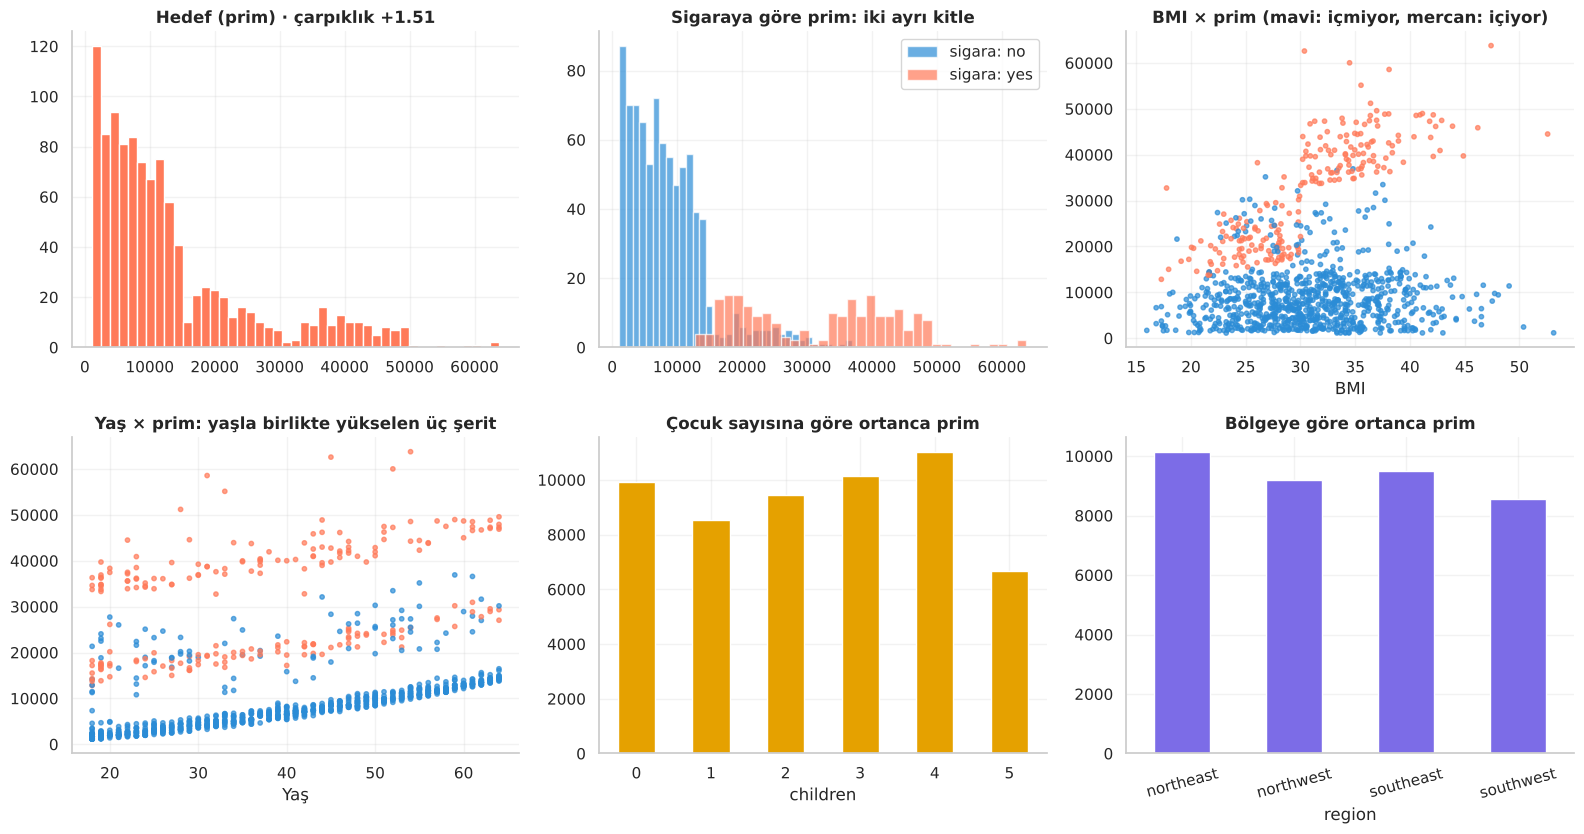

,kişi,ortanca,ortalama,çarpıklık
smoker,,,,
no,850,7352.0,8568.3,1.5
yes,219,34254.1,31938.1,0.2


📄 Rapor → outputs/reports/03_sigara_gruplari.csv


In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
sig = egitim["smoker"].map({"yes": RENK["mercan"], "no": RENK["gok"]})
ax[0, 0].hist(ytr, bins=45, color=RENK["mercan"], edgecolor="white"); ax[0, 0].set_title(f"Hedef (prim) · çarpıklık {stats.skew(ytr):+.2f}")
for g, r in [("no", RENK["gok"]), ("yes", RENK["mercan"])]:
    ax[0, 1].hist(egitim.loc[egitim.smoker == g, "charges"], bins=35, alpha=.7, color=r, label=f"sigara: {g}")
ax[0, 1].legend(); ax[0, 1].set_title("Sigaraya göre prim: iki ayrı kitle")
ax[0, 2].scatter(egitim["bmi"], egitim["charges"], c=sig, s=10, alpha=.7); ax[0, 2].set_title("BMI × prim (mavi: içmiyor, mercan: içiyor)"); ax[0, 2].set_xlabel("BMI")
ax[1, 0].scatter(egitim["age"], egitim["charges"], c=sig, s=10, alpha=.7); ax[1, 0].set_title("Yaş × prim: yaşla birlikte yükselen üç şerit"); ax[1, 0].set_xlabel("Yaş")
egitim.groupby("children")["charges"].median().plot.bar(ax=ax[1, 1], color=RENK["amber"]); ax[1, 1].set_title("Çocuk sayısına göre ortanca prim"); ax[1, 1].tick_params(axis="x", rotation=0)
egitim.groupby("region")["charges"].median().plot.bar(ax=ax[1, 2], color=RENK["mor"]); ax[1, 2].set_title("Bölgeye göre ortanca prim"); ax[1, 2].tick_params(axis="x", rotation=15)
plt.tight_layout(); kaydet(fig, "01_eda_genel"); plt.show()

grup = egitim.groupby("smoker")["charges"].agg(["count", "median", "mean", lambda s: stats.skew(s)]); grup.columns = ["kişi", "ortanca", "ortalama", "çarpıklık"]
display(grup.round(1)); rapor_kaydet(grup, "03_sigara_gruplari")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Çarpıklığın bir kısmı gerçek bir kitle ayrımından gelir:** sigara içenlerin primi içmeyenlere göre çok yüksektir ve yukarıdaki iki histogram birbirinden ayrışır. Her grubun **kendi içindeki** çarpıklık, genel çarpıklıktan farklıdır. Bu, dönüşümün **tek başına yetmeyeceği** anlamına gelir: model, sigara ve BMI etkileşimini de öğrenmelidir. Bu, 6. ve 7. bölümlerin ana temasıdır.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/proje_05.svg" width="100%" alt="Bölüm 5 · Dönüşüm laboratuvarı">
</p>

### 📐 5.1 · Hedef İçin Altı Aday Dönüşüm

Aynı eğitim hedefine altı farklı dönüşüm uyguluyoruz ve çarpıklık, basıklık ve «çana uyum» (Q-Q grafiğindeki korelasyon) puanına bakıyoruz. λ'lar **yalnızca eğitim hedefinden** hesaplanır.

| Dönüşüm | Fikir |
|:--|:--|
| Ham | Dokunma |
| Karekök | Hafif sıkıştırma (λ = 0,5) |
| Logaritma | Güçlü sıkıştırma (λ = 0) |
| **Box-Cox** | λ'yı veri belirler (y > 0) |
| **Yeo-Johnson** | λ'yı veri belirler (her değerde çalışır) |
| Kantil (normal) | Sıraya göre doğrudan çana eşler; parametresiz ve sınırsız esnek |

Box-Cox λ = 0.051 (%95 güven aralığı -0.010 … 0.113)
Yeo-Johnson λ = 0.051   (y > 0 olduğundan Yeo-Johnson ≈ Box-Cox(y+1); λ çok yakın çıkmalı)


,Çarpıklık,Basıklık (fazla),Q-Q R²
Dönüşüm,,,
Ham,1.514,1.652,0.819
Karekök,0.783,-0.082,0.938
Logaritma,-0.106,-0.631,0.985
Box-Cox,-0.010,-0.649,0.986
Yeo-Johnson,-0.010,-0.649,0.986
Kantil (normal),-0.000,-0.026,1.000


📄 Rapor → outputs/reports/04_donusum_laboratuvari.csv


💾 Kaydedildi → outputs/figures/02_donusum_laboratuvari.png


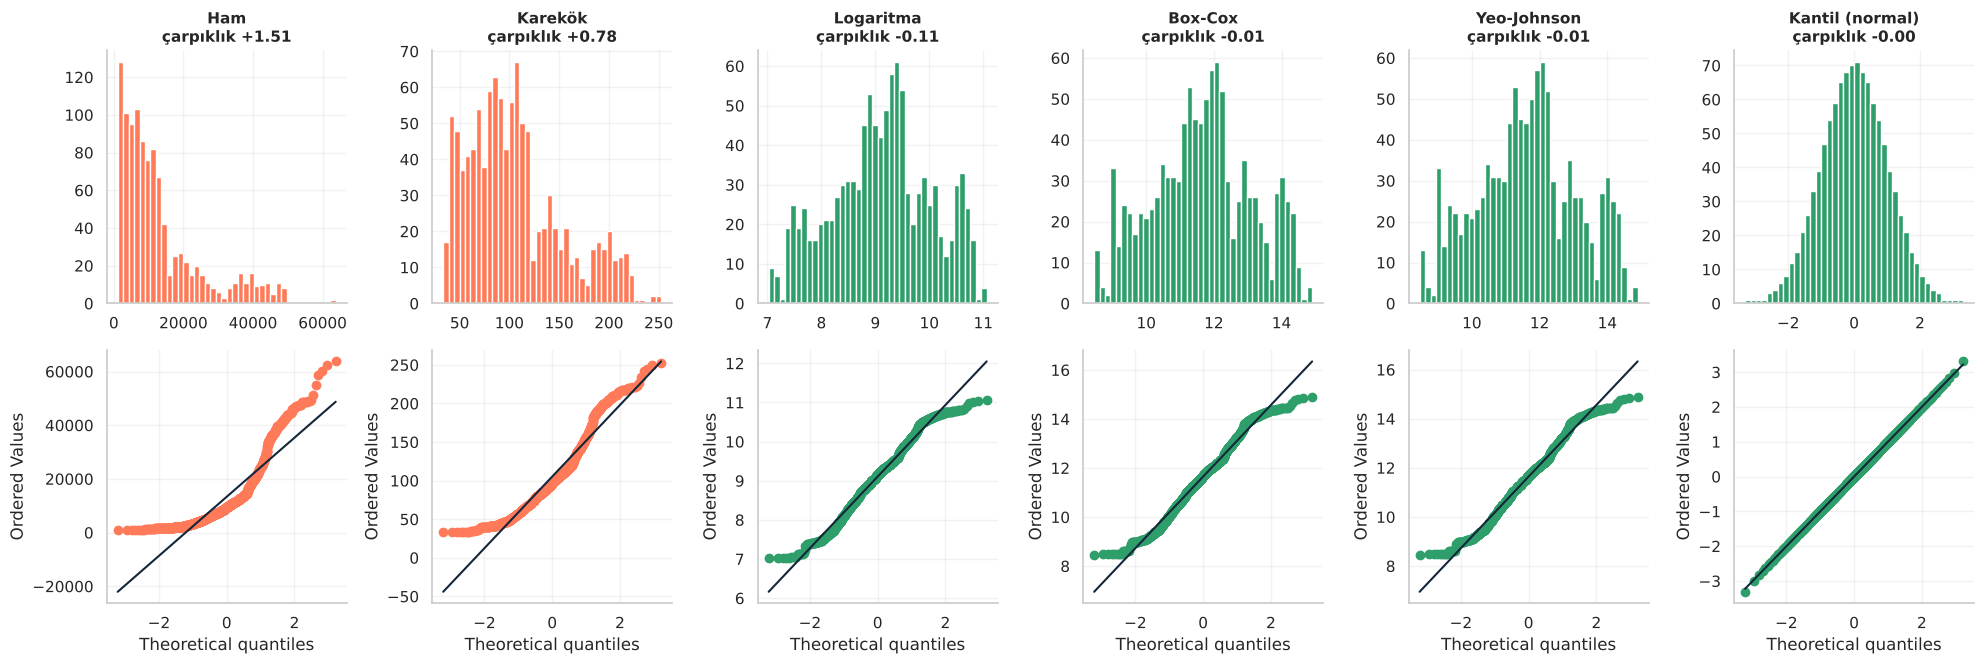

In [6]:
from scipy.stats import boxcox_normmax
lam_bc, (lam_alt, lam_ust) = stats.boxcox(ytr, alpha=0.05)[1:]
yj_pt = PowerTransformer("yeo-johnson", standardize=False).fit(ytr.reshape(-1, 1))
print(f"Box-Cox λ = {lam_bc:.3f} (%95 güven aralığı {lam_alt:.3f} … {lam_ust:.3f})")
print(f"Yeo-Johnson λ = {yj_pt.lambdas_[0]:.3f}   (y > 0 olduğundan Yeo-Johnson ≈ Box-Cox(y+1); λ çok yakın çıkmalı)")

adaylar = {
    "Ham": ytr,
    "Karekök": np.sqrt(ytr),
    "Logaritma": np.log(ytr),
    "Box-Cox": stats.boxcox(ytr, lmbda=lam_bc),
    "Yeo-Johnson": yj_pt.transform(ytr.reshape(-1, 1)).ravel(),
    "Kantil (normal)": stats.norm.ppf((stats.rankdata(ytr) - .5) / len(ytr)),
}
satirlar = []
for ad, v in adaylar.items():
    (_, _), (_, _, r) = stats.probplot(v, dist="norm")
    satirlar.append((ad, stats.skew(v), stats.kurtosis(v), r ** 2))
lab = pd.DataFrame(satirlar, columns=["Dönüşüm", "Çarpıklık", "Basıklık (fazla)", "Q-Q R²"]).set_index("Dönüşüm")
display(lab.round(3)); rapor_kaydet(lab, "04_donusum_laboratuvari")

fig, ax = plt.subplots(2, 6, figsize=(20, 6.8))
for j, (ad, v) in enumerate(adaylar.items()):
    r = RENK["nane"] if abs(stats.skew(v)) < 0.3 else RENK["mercan"]
    ax[0, j].hist(v, bins=40, color=r, edgecolor="white"); ax[0, j].set_title(f"{ad}\nçarpıklık {stats.skew(v):+.2f}", fontsize=11)
    stats.probplot(v, dist="norm", plot=ax[1, j]); ax[1, j].get_lines()[0].set_color(r); ax[1, j].get_lines()[1].set_color(RENK["koyu"]); ax[1, j].set_title("")
plt.tight_layout(); kaydet(fig, "02_donusum_laboratuvari"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Box-Cox ve Yeo-Johnson **aynı** λ'yı buldu (≈ 0,05); çünkü bu hedefte sıfır yok ve λ log'a çok yakın. **Çarpıklık +1,5'ten 0'a iner, çana uyum (Q-Q R²) 0,82'den 0,99'a çıkar.** Kantil dönüşümü sıraya göre doğrudan çana eşlediği için «mükemmel» (R² = 1) görünür; ama o, **ters dönüşümde eğitimdeki aralığın dışına çıkamaz** (9. bölümde göreceğiz). Üstelik **çarpıklığı düzeltmek, tahmin hatasını düzeltmekle aynı şey değildir:** histogramda hâlâ birden çok tepe vardır; sigara içenler ve içmeyenler farklı kitlelerdir.

</td></tr></table>

### 🔄 5.2 · λ Ne Kadar Güvenilir? Bootstrap

Bootstrap λ: ortanca 0.051, %2,5–%97,5 aralığı [0.015, 0.089]
Sigara içmeyenlerde λ = 0.174 | içenlerde λ = 0.437 → iki kitle farklı lastik istiyor


💾 Kaydedildi → outputs/figures/03_lambda_guveni.png


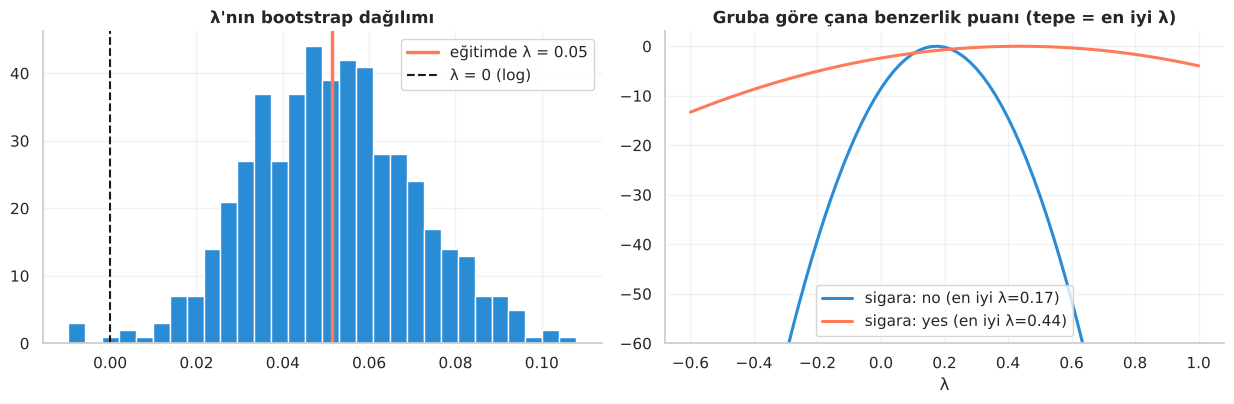

In [7]:
rng = np.random.RandomState(RANDOM_STATE)
boot_lam = np.array([boxcox_normmax(ytr[rng.randint(0, len(ytr), len(ytr))], method="mle") for _ in range(500)])
print(f"Bootstrap λ: ortanca {np.median(boot_lam):.3f}, %2,5–%97,5 aralığı [{np.percentile(boot_lam, 2.5):.3f}, {np.percentile(boot_lam, 97.5):.3f}]")

# sigara gruplarında λ ayrı ayrı
lam_gr = {g: stats.boxcox(egitim.loc[egitim.smoker == g, "charges"])[1] for g in ["no", "yes"]}
print("Sigara içmeyenlerde λ =", round(lam_gr["no"], 3), "| içenlerde λ =", round(lam_gr["yes"], 3), "→ iki kitle farklı lastik istiyor")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax[0].hist(boot_lam, bins=30, color=RENK["gok"], edgecolor="white"); ax[0].axvline(lam_bc, color=RENK["mercan"], lw=2.5, label=f"eğitimde λ = {lam_bc:.2f}"); ax[0].axvline(0, color="k", ls="--", label="λ = 0 (log)")
ax[0].set_title("λ'nın bootstrap dağılımı"); ax[0].legend()
lams = np.linspace(-0.6, 1.0, 81)
for g, r in [("no", RENK["gok"]), ("yes", RENK["mercan"])]:
    v = egitim.loc[egitim.smoker == g, "charges"].to_numpy(); p = np.array([stats.boxcox_llf(l, v) for l in lams])
    ax[1].plot(lams, p - p.max(), color=r, lw=2.2, label=f"sigara: {g} (en iyi λ={lam_gr[g]:.2f})")
ax[1].set_ylim(-60, 3); ax[1].set_title("Gruba göre çana benzerlik puanı (tepe = en iyi λ)"); ax[1].set_xlabel("λ"); ax[1].legend()
plt.tight_layout(); kaydet(fig, "03_lambda_guveni"); plt.show()

### 🧰 5.3 · Özellik Tarafı: Hangi Sütun Dönüşümden Yararlanır?

Hedef dışında **sayısal özellikler** de çarpık olabilir. `age` ve `bmi` pozitiftir, `children` ise sıfır içerir. Yeo-Johnson üçüne de uygulanabilir.

,en küçük,Çarpıklık (ham),Çarpıklık (Yeo-Johnson),λ
Sütun,,,,
age,18.00,0.079,-0.094,0.588
bmi,15.96,0.268,-0.006,0.487
children,0.00,0.852,0.096,-0.334


📄 Rapor → outputs/reports/05_ozellik_donusumu.csv


💾 Kaydedildi → outputs/figures/04_ozellik_donusumu.png


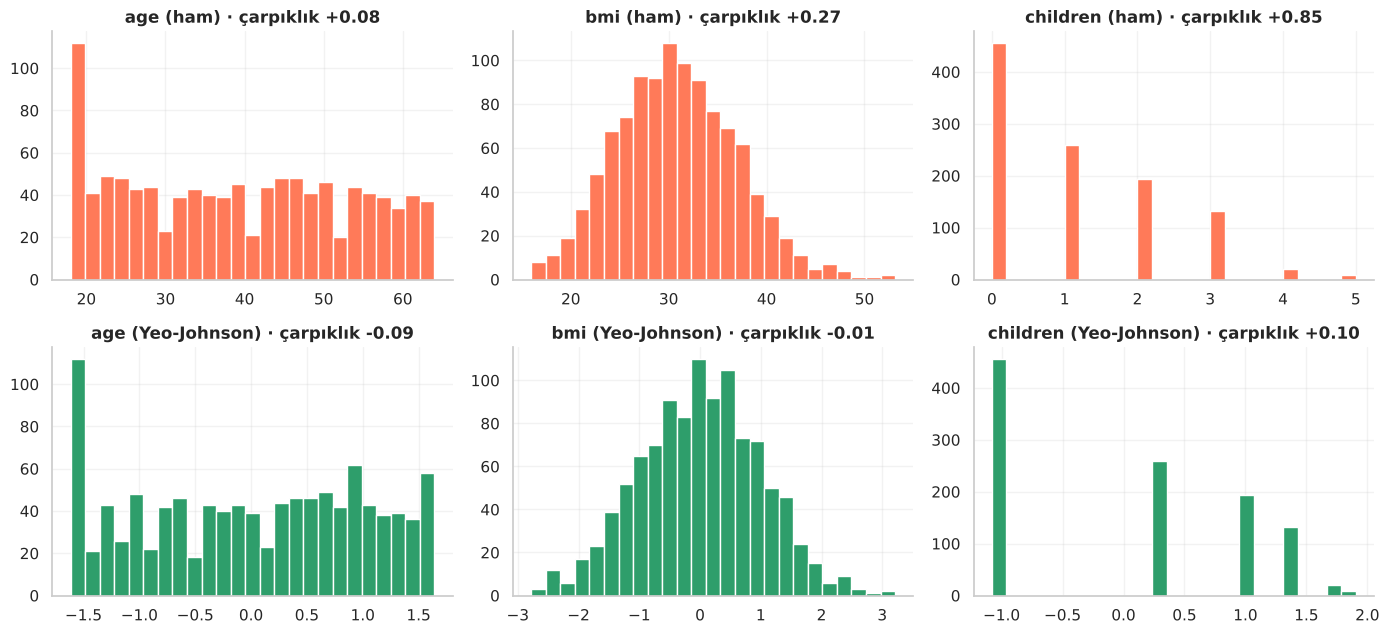

In [8]:
oz_say = ["age", "bmi", "children"]
satirlar = []
for c in oz_say:
    v = Xtr[c].to_numpy(float)
    z = PowerTransformer("yeo-johnson").fit_transform(v.reshape(-1, 1)).ravel()
    satirlar.append((c, v.min(), stats.skew(v), stats.skew(z), PowerTransformer("yeo-johnson", standardize=False).fit(v.reshape(-1, 1)).lambdas_[0]))
ozt = pd.DataFrame(satirlar, columns=["Sütun", "en küçük", "Çarpıklık (ham)", "Çarpıklık (Yeo-Johnson)", "λ"]).set_index("Sütun")
display(ozt.round(3)); rapor_kaydet(ozt, "05_ozellik_donusumu")

fig, ax = plt.subplots(2, 3, figsize=(14, 6.5))
for j, c in enumerate(oz_say):
    v = Xtr[c].to_numpy(float); z = PowerTransformer("yeo-johnson").fit_transform(v.reshape(-1, 1)).ravel()
    ax[0, j].hist(v, bins=25, color=RENK["mercan"], edgecolor="white"); ax[0, j].set_title(f"{c} (ham) · çarpıklık {stats.skew(v):+.2f}")
    ax[1, j].hist(z, bins=25, color=RENK["nane"], edgecolor="white"); ax[1, j].set_title(f"{c} (Yeo-Johnson) · çarpıklık {stats.skew(z):+.2f}")
plt.tight_layout(); kaydet(fig, "04_ozellik_donusumu"); plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

`age` ve `bmi` zaten **hemen hemen simetrik**; dönüşüm onlara az şey katar. `children` bir **sayım** değişkenidir (0–5); Yeo-Johnson onu sürekli bir çana çeviremez, yalnızca ölçeğini değiştirir. Ayrıca **ağaç tabanlı modeller** için özellik dönüşümünün hiçbir etkisi olmadığını kavram dersinde gördük. Özellik tarafındaki dönüşümü 9.3'te **ölçeğe duyarlı modellerde** deneyeceğiz.

</td></tr></table>

### 🛡️ 5.4 · Sızıntı Laboratuvarı: λ'yı Tüm Veriden Hesaplamak Ne Kadar Zarar Verir?

Eğitim λ'sı ile (eğitim + test birlikte) hesaplanan λ'yı karşılaştırıyoruz. Test setine **yalnızca bu bölümde, λ'yı hesaplamak için değil, sızıntının büyüklüğünü ölçmek için** bakıyoruz; modele hiçbir şey taşınmaz.

In [9]:
lam_hepsi = stats.boxcox(np.r_[ytr, yte])[1]
z_egitimli = stats.boxcox(yte, lmbda=lam_bc)
z_sizintili = stats.boxcox(yte, lmbda=lam_hepsi)
print(f"λ (yalnızca eğitim): {lam_bc:.4f}   λ (eğitim+test): {lam_hepsi:.4f}   fark: {abs(lam_bc - lam_hepsi):.4f}")
print(f"Test hedefinin çarpıklığı → eğitim λ'sıyla {stats.skew(z_egitimli):+.3f} | sızıntılı λ ile {stats.skew(z_sizintili):+.3f}")
print("Bu veride sızıntı küçük (n = 1.070 eğitim, λ oturaklı). Ama n = 30 olsaydı? Kavram dersinde λ'nın %5–%95 aralığı −0,17…+0,26 idi.")
print("Kural değişmez: λ'yı her katta yalnızca eğitim kısmından öğren.")

λ (yalnızca eğitim): 0.0515   λ (eğitim+test): 0.0435   fark: 0.0079
Test hedefinin çarpıklığı → eğitim λ'sıyla +0.071 | sızıntılı λ ile +0.057
Bu veride sızıntı küçük (n = 1.070 eğitim, λ oturaklı). Ama n = 30 olsaydı? Kavram dersinde λ'nın %5–%95 aralığı −0,17…+0,26 idi.
Kural değişmez: λ'yı her katta yalnızca eğitim kısmından öğren.


<a id="p6"></a>

<p align="center">
  <img src="assets/proje_06.svg" width="100%" alt="Bölüm 6 · Boru hattı">
</p>

### 🧱 6.1 · Sızıntısız Boru Hattı

Tüm adımlar **tek bir boru hattında** durur; her doğrulama katında yeniden eğitilir:

1. `OzellikUretici`: ham tabloyu sayısallaştırır (sigara, cinsiyet, bölge tek-sıcak). Hedefe **hiç bakmaz**.
2. (Ölçeğe duyarlı modeller için) `StandardScaler` ya da `Yeo-Johnson`.
3. Model.
4. **`TransformedTargetRegressor`**: hedefi dönüştürür, modeli dönüşmüş hedefle eğitir, tahmini **dolara geri çevirir**. λ her katta **yalnızca o katın eğitim kısmından** öğrenilir.

<p align="center">
  <img src="assets/diyagram_hedef_donusumu.svg" width="100%" alt="Hedef dönüşümlü regresör">
</p>

### 🧪 6.2 · Özellik Kümesi Kararı (kural önceden yazıldı)

> **Kural:** İki temsilci modelde (Ridge ve LightGBM; ikisi de ham hedefle) 5×2 katlı çapraz doğrulama yapılır. **Ek özellikler** (`obez` bayrağı ve `sigara × obez` etkileşimi), **iki modelden birinin RMSE'sini ≥ %2 iyileştiriyor** ve ötekini **≥ %2 bozmuyorsa** kalır; aksi hâlde çıkarılır.

In [10]:
KATLAR = list(RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(Xtr))      # tüm yarışlar aynı katlar
KATLAR_TAZE = list(RepeatedKFold(n_splits=5, n_repeats=2, random_state=7).split(Xtr))           # "taze" katlar: seçimde kullanılmayan düzen

def kos(ad, tahminci, olcek, hedef, ek=True, yj=False, katlar=KATLAR, oof_tur=5):
    """Bir (model, hedef) çiftini katlarda değerlendirir; ilk turun dışı-kat tahminlerini de saklar."""
    t0 = time.time(); olc_listesi = []; oof = np.full(len(ytr), np.nan)
    for k, (a, b) in enumerate(katlar):
        m = sy.boru_hatti(ad, tahminci, olcek, ek=ek, hedef=hedef, yj_ozellik=yj).fit(Xtr.iloc[a], ytr[a])
        p = m.predict(Xtr.iloc[b]); olc_listesi.append(olc(ytr[b], p))
        if k < oof_tur: oof[b] = p
    d = pd.DataFrame(olc_listesi).mean().to_dict()
    d.update(ad=ad, hedef=hedef if isinstance(hedef, str) else f"λ={hedef}", sure=time.time() - t0, oof=oof, ek=ek, yj=yj)
    return d

zoo = sy.model_zoo(RANDOM_STATE)
rs = []
for ek in (False, True):
    for ad in ("Ridge", "LightGBM"):
        e, o = zoo[ad]; rs.append(kos(ad, e, o, "ham", ek=ek))
ozk = pd.DataFrame(rs)[["ad", "ek", "RMSE", "MAE", "RMSLE", "R2"]]
display(ozk.round(3))
iy = {ad: 1 - ozk[(ozk.ad == ad) & ozk.ek]["RMSE"].iloc[0] / ozk[(ozk.ad == ad) & ~ozk.ek]["RMSE"].iloc[0] for ad in ("Ridge", "LightGBM")}
print({k: f"%{v*100:+.1f}" for k, v in iy.items()}, "(RMSE iyileşmesi)")
EK_KALSIN = (max(iy.values()) >= 0.02) and (min(iy.values()) > -0.02)
print("Karar → ek özellikler", "KALSIN" if EK_KALSIN else "ÇIKSIN")
rapor_kaydet(ozk, "06_ozellik_karari", index=False)

,ad,ek,RMSE,MAE,RMSLE,R2
0,Ridge,False,6309.998,4390.377,1.010,0.725
1,LightGBM,False,4830.603,2781.915,0.461,0.837
2,Ridge,True,4725.766,2698.465,0.423,0.844
3,LightGBM,True,4838.534,2764.484,0.463,0.836


{'Ridge': '%+25.1', 'LightGBM': '%-0.2'} (RMSE iyileşmesi)
Karar → ek özellikler KALSIN
📄 Rapor → outputs/reports/06_ozellik_karari.csv


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Doğrusal modeller için «sigara × obez» etkileşimi çok değerlidir**, çünkü doğrusal bir model bu etkileşimi kendi başına **bulamaz**; ağaç tabanlı modeller ise bulur. Aynı ek özellik iki model ailesine farklı hizmet eder. Bu, aşağıdaki yarışta doğrusal modellerin ham hedefle bile iyi çıkmasının sebebidir.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/proje_07.svg" width="100%" alt="Bölüm 7 · Büyük yarış">
</p>

### 🏁 7.1 · Aynı Parkur, Aynı Katlar, İki Senaryo

27 algoritmayı (+ ortalamayı tahmin eden **taban**) **aynı boru hattında**, **aynı 5×2 katlarda** yarıştırıyoruz; iki senaryo:

- **A · Ham hedef:** yalnızca standartlaştırma (doğrusal ölçek değişimi; modelin ölçek sorunu yaşamaması için).
- **B · Box-Cox hedef:** λ her katta eğitimden öğrenilir, tahmin dolara geri çevrilir.

Tüm ölçütler **dolar dünyasında** hesaplanır (tahmin geri çevrildikten sonra); böylece iki senaryo birebir karşılaştırılabilir. Hiperparametreler **makul varsayılan** düzeyindedir; ayar 10. bölümde.

In [11]:
ensemble = sy.topluluklar(RANDOM_STATE)
tum_modeller = dict(zoo); tum_modeller.update({ad: (m, False) for ad, m in ensemble.items()})
alg_sayisi = len(tum_modeller) - 1      # taban hariç
print("Algoritma sayısı (taban hariç):", alg_sayisi)

t0 = time.time()
isler = [delayed(kos)(ad, e, o, h, ek=EK_KALSIN) for ad, (e, o) in tum_modeller.items() for h in ("ham", "box-cox")]
sonuclar = Parallel(n_jobs=N_IS)(isler)
print(f"Toplam süre: {time.time() - t0:.0f} sn | {len(sonuclar)} (model × senaryo) değerlendirildi")

df = pd.DataFrame(sonuclar)
OOF = {(r["ad"], r["hedef"]): r["oof"] for r in sonuclar}
yaris = df.pivot(index="ad", columns="hedef", values=["RMSE", "MAE", "RMSLE", "R2"])
yaris[("sure", "sn")] = df.groupby("ad")["sure"].sum()
yaris[("sıra", "A·ham")] = yaris[("RMSE", "ham")].rank().astype(int); yaris[("sıra", "B·Box-Cox")] = yaris[("RMSE", "box-cox")].rank().astype(int)
yaris = yaris.sort_values(("RMSE", "ham"))
rapor_kaydet(yaris, "07_buyuk_yaris")
goster = yaris.copy(); goster.columns = [f"{a} · {'A ham' if b=='ham' else 'B Box-Cox' if b=='box-cox' else b}" for a, b in goster.columns]
display(goster.round(3).style.background_gradient(subset=[c for c in goster.columns if c.startswith("RMSE")], cmap="RdYlGn_r").format(precision=3))

Algoritma sayısı (taban hariç): 27


Toplam süre: 38 sn | 56 (model × senaryo) değerlendirildi
📄 Rapor → outputs/reports/07_buyuk_yaris.csv


,RMSE · B Box-Cox,RMSE · A ham,MAE · B Box-Cox,MAE · A ham,RMSLE · B Box-Cox,RMSLE · A ham,R2 · B Box-Cox,R2 · A ham,sure · sn,sıra · A·ham,sıra · B·Box-Cox
ad,,,,,,,,,,,
Yığın (Ridge meta),4715.836,4643.052,2247.268,2623.269,0.385,0.422,0.844,0.849,32.178,1,1
Oylama (4 model),4902.607,4675.520,2295.938,2461.965,0.387,0.416,0.832,0.847,6.822,2,11
Polinom(2) + Ridge,4910.063,4703.839,2488.795,2634.749,0.390,0.479,0.832,0.845,0.373,3,12
Gauss süreci,4813.185,4709.836,2372.177,2664.281,0.391,0.423,0.838,0.845,38.577,4,6
SGD regresör,7757.055,4723.819,3922.030,2682.164,0.436,0.420,0.584,0.844,0.312,5,22
ElasticNet,7572.340,4725.689,3833.344,2724.189,0.436,0.425,0.604,0.844,0.336,6,21
Bayes Ridge,7764.283,4725.728,3919.603,2700.462,0.436,0.423,0.584,0.844,0.331,7,23
Ridge,7805.116,4725.766,3933.340,2698.465,0.436,0.423,0.579,0.844,0.373,8,24
Doğrusal regresyon,7821.000,4725.869,3938.707,2697.381,0.436,0.423,0.577,0.844,0.348,9,25


💾 Kaydedildi → outputs/figures/05_buyuk_yaris.png


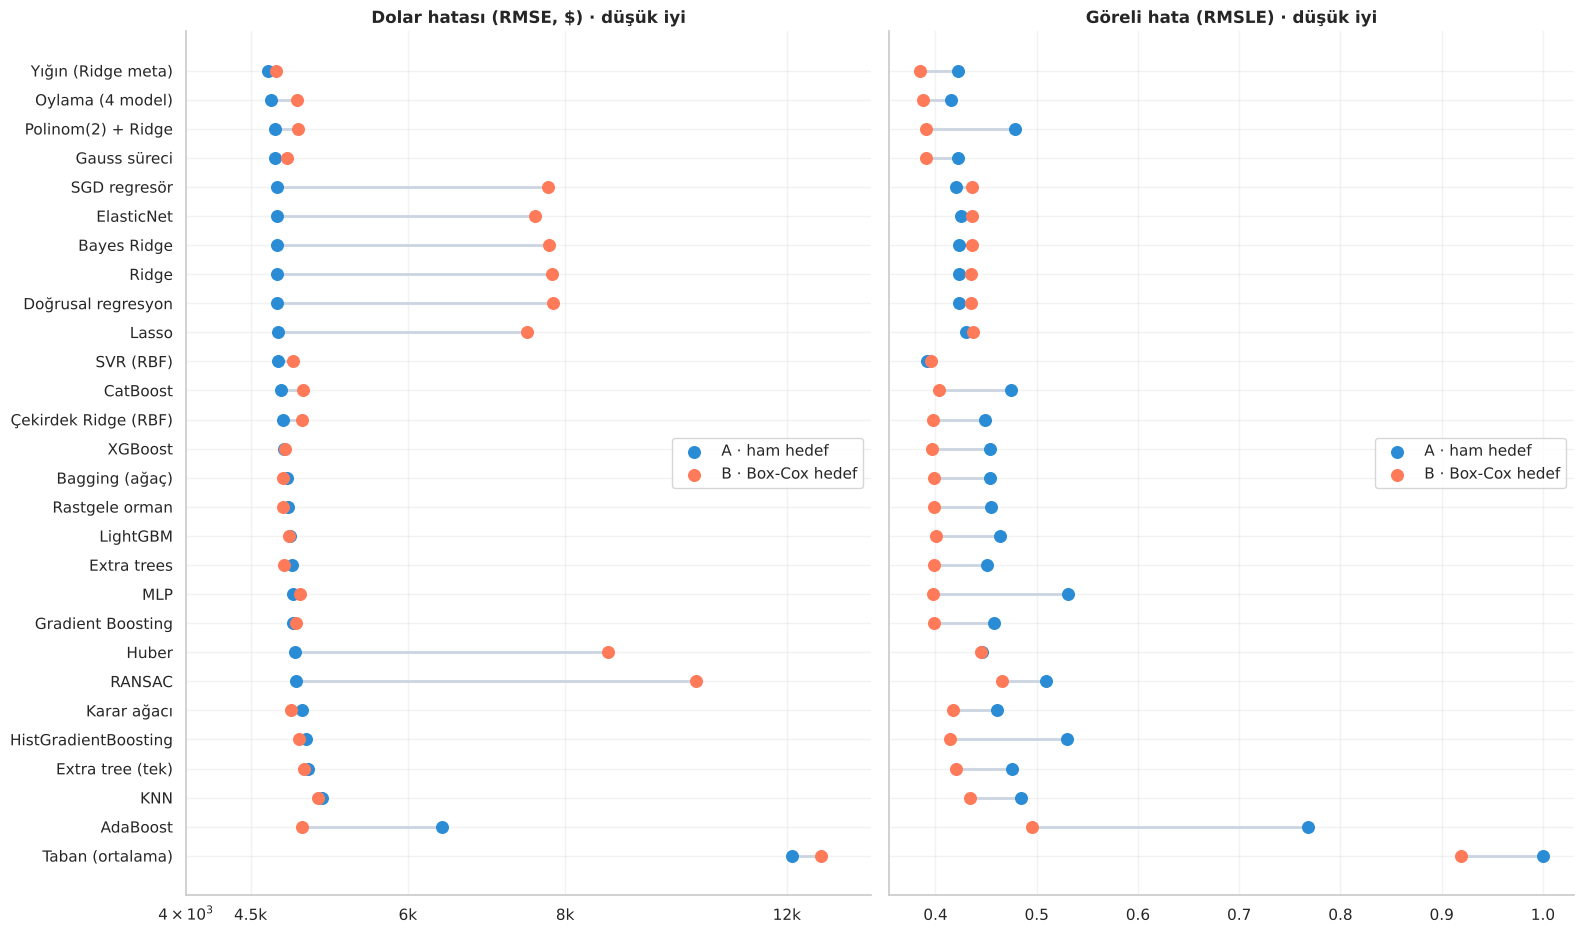

In [12]:
# ── Görsel: iki senaryo yan yana (RMSE ve RMSLE) ──────────────
sira = yaris[("RMSE", "ham")].sort_values().index.tolist()[::-1]
fig, ax = plt.subplots(1, 2, figsize=(16, 9.5), sharey=True)
for a, olcut, baslik in [(ax[0], "RMSE", "Dolar hatası (RMSE, $) · düşük iyi"), (ax[1], "RMSLE", "Göreli hata (RMSLE) · düşük iyi")]:
    y = np.arange(len(sira))
    ham_v = yaris.loc[sira, (olcut, "ham")].to_numpy(); bc_v = yaris.loc[sira, (olcut, "box-cox")].to_numpy()
    a.hlines(y, ham_v, bc_v, color="#CBD5E1", lw=2)
    a.scatter(ham_v, y, s=70, color=RENK["gok"], label="A · ham hedef", zorder=3)
    a.scatter(bc_v, y, s=70, color=RENK["mercan"], label="B · Box-Cox hedef", zorder=3)
    a.set_yticks(y); a.set_yticklabels(sira); a.set_title(baslik); a.legend(loc="center right")
    if olcut == "RMSE": a.set_xscale("log"); a.set_xlim(4000, 14000); a.set_xticks([4500, 6000, 8000, 12000]); a.set_xticklabels(["4.5k", "6k", "8k", "12k"])
plt.tight_layout(); kaydet(fig, "05_buyuk_yaris"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Okuma rehberi:** mavi nokta ham hedefi, mercan nokta Box-Cox hedefi gösterir; aralarındaki çizgi **dönüşümün farkıdır**. Soldaki grafik (dolar hatası) ile sağdaki grafik (göreli hata) **aynı modellerde farklı hikâye** anlatabilir. Bir modelin mercan noktası solda mavinin **sağına**, sağda ise **soluna** düşüyorsa, dönüşüm onu **dolarda kötüleştirip göreli hatada iyileştiriyor** demektir. Bu ayrışmanın nedenini 9. bölümde λ düğmesini çevirerek inceleyeceğiz.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/proje_08.svg" width="100%" alt="Bölüm 8 · Yarışın röntgeni">
</p>

### 🔄 8.1 · Taze Katlarda Sıralama Değişiyor mu?

Büyük yarışta sıralama, **seçimde kullandığımız katlara** bağlıdır. Aynı veriyi **farklı bir tohumla** bölünmüş «taze» katlarda tekrar koşturup sıralamanın **kararlı** olup olmadığına bakıyoruz.

In [13]:
ilk = yaris[("RMSE", "ham")].combine(yaris[("RMSE", "box-cox")], min).sort_values().index[:12].tolist()
ilk = [a for a in ilk if a != "Taban (ortalama)"]
isler = [delayed(kos)(a, tum_modeller[a][0], tum_modeller[a][1], h, ek=EK_KALSIN, katlar=KATLAR_TAZE) for a in ilk for h in ("ham", "box-cox")]
taze = pd.DataFrame(Parallel(n_jobs=N_IS)(isler))
tz = taze.pivot(index="ad", columns="hedef", values="RMSE").loc[ilk]
tz["Eski sıra (A)"] = yaris.loc[ilk, ("sıra", "A·ham")].values; tz["Eski sıra (B)"] = yaris.loc[ilk, ("sıra", "B·Box-Cox")].values
tz["Taze sıra (A)"] = tz["ham"].rank().astype(int); tz["Taze sıra (B)"] = tz["box-cox"].rank().astype(int)
tz = tz.rename(columns={"ham": "RMSE taze A", "box-cox": "RMSE taze B"})
display(tz.round(1)); rapor_kaydet(tz, "08_taze_katlar")
for s in "AB":
    r = stats.spearmanr(tz[f"Eski sıra ({s})"], tz[f"Taze sıra ({s})"])[0]
    print(f"Senaryo {s}: eski ↔ taze sıra korelasyonu (Spearman) = {r:.2f}")

hedef,RMSE taze B,RMSE taze A,Eski sıra (A),Eski sıra (B),Taze sıra (A),Taze sıra (B)
ad,,,,,,
Yığın (Ridge meta),4805.0,4691.8,1,1,1,1
Oylama (4 model),4951.1,4720.6,2,11,2,4
Polinom(2) + Ridge,4959.6,4771.7,3,12,10,5
Gauss süreci,4876.9,4742.3,4,6,3,2
SGD regresör,7922.8,4753.5,5,22,6,12
ElasticNet,7671.4,4751.6,6,21,4,8
Bayes Ridge,7863.0,4754.7,7,23,7,9
Ridge,7904.5,4754.8,8,24,8,10
Doğrusal regresyon,7920.6,4754.9,9,25,9,11


📄 Rapor → outputs/reports/08_taze_katlar.csv
Senaryo A: eski ↔ taze sıra korelasyonu (Spearman) = 0.72
Senaryo B: eski ↔ taze sıra korelasyonu (Spearman) = 0.90


### 🎲 8.2 · Fark Şans mı, Gerçek mi? Eşleştirilmiş Bootstrap

Her model için ham ve Box-Cox senaryolarının **dışı-kat tahminlerini** (aynı kişiler üzerinde) alıp kişileri 1.000 kez yeniden örnekleyerek **ΔRMSE** ve **ΔRMSLE** (Box-Cox − ham) için %95 aralık çıkarıyoruz. Aralık **sıfırı kesiyorsa** fark şanstan ayırt edilemez.

,dRMSE,dRMSE_alt,dRMSE_ust,dRMSLE,dRMSLE_alt,dRMSLE_ust,Dolar (RMSE) hükmü,Göreli (RMSLE) hükmü
ad,,,,,,,,
AdaBoost,-1546.467,-1828.888,-1276.476,-0.292,-0.324,-0.256,Box-Cox daha iyi,Box-Cox daha iyi
Karar ağacı,-136.521,-253.437,-30.323,-0.050,-0.072,-0.028,Box-Cox daha iyi,Box-Cox daha iyi
Extra trees,-56.277,-114.529,1.884,-0.050,-0.066,-0.034,ayırt edilemez,Box-Cox daha iyi
Rastgele orman,-42.963,-105.410,20.438,-0.052,-0.069,-0.037,ayırt edilemez,Box-Cox daha iyi
HistGradientBoosting,-41.617,-128.385,46.461,-0.159,-0.267,-0.088,ayırt edilemez,Box-Cox daha iyi
KNN,-32.776,-96.382,28.671,-0.050,-0.065,-0.035,ayırt edilemez,Box-Cox daha iyi
Bagging (ağaç),-28.393,-92.508,35.454,-0.052,-0.068,-0.036,ayırt edilemez,Box-Cox daha iyi
LightGBM,-1.220,-76.415,76.867,-0.064,-0.082,-0.047,ayırt edilemez,Box-Cox daha iyi
Gradient Boosting,9.634,-86.718,109.608,-0.059,-0.081,-0.041,ayırt edilemez,Box-Cox daha iyi


📄 Rapor → outputs/reports/09_bootstrap_farklar.csv

Dolar hatası: {'Box-Cox daha kötü': 15, 'ayırt edilemez': 10, 'Box-Cox daha iyi': 2}
Göreli hata  : {'Box-Cox daha iyi': 19, 'ayırt edilemez': 8}


💾 Kaydedildi → outputs/figures/07_bootstrap_farklar.png


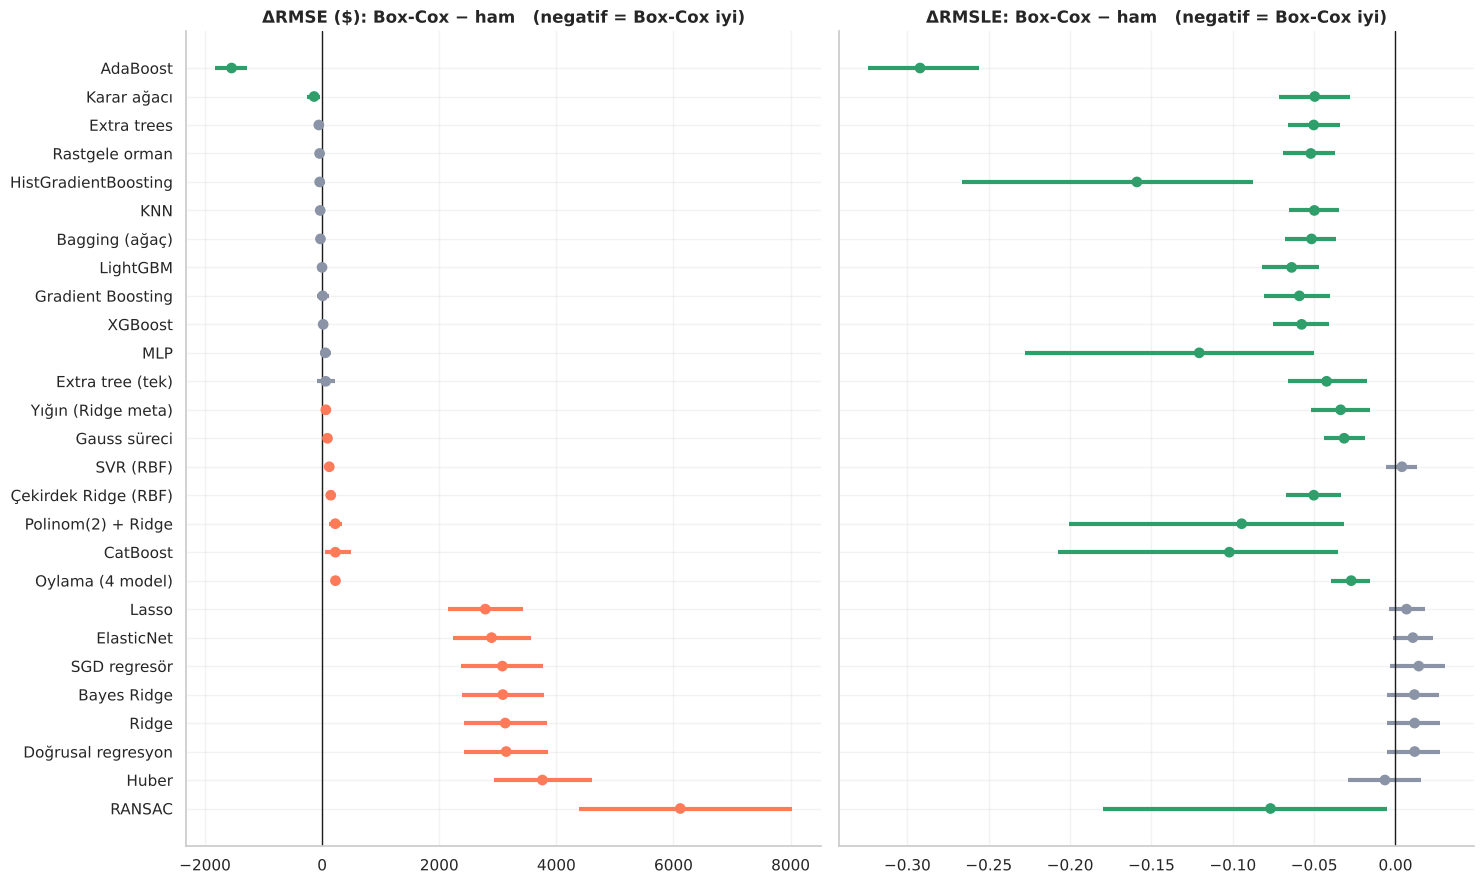

In [14]:
rng = np.random.RandomState(RANDOM_STATE)
B = 1000; n = len(ytr)
idx = rng.randint(0, n, (B, n))

def fark_ci(pa, pb, fn):
    """fn: (y, p) -> skaler; (B boyutlu) eşleştirilmiş bootstrap farkı pb - pa."""
    d = np.array([fn(ytr[i], pb[i]) - fn(ytr[i], pa[i]) for i in idx])
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

rmse_f = lambda y, p: np.sqrt(np.mean((y - p) ** 2))
rmsle_f = lambda y, p: np.sqrt(np.mean((np.log1p(np.clip(p, 0, None)) - np.log1p(y)) ** 2))
satir = []
for ad in yaris.index:
    if ad.startswith("Taban"): continue
    pa, pb = OOF[(ad, "ham")], OOF[(ad, "box-cox")]
    r = fark_ci(pa, pb, rmse_f); l = fark_ci(pa, pb, rmsle_f)
    satir.append((ad, *r, *l))
bs = pd.DataFrame(satir, columns=["ad", "dRMSE", "dRMSE_alt", "dRMSE_ust", "dRMSLE", "dRMSLE_alt", "dRMSLE_ust"]).set_index("ad")
def etiket(alt, ust): return "Box-Cox daha iyi" if ust < 0 else ("Box-Cox daha kötü" if alt > 0 else "ayırt edilemez")
bs["Dolar (RMSE) hükmü"] = [etiket(a, u) for a, u in zip(bs.dRMSE_alt, bs.dRMSE_ust)]
bs["Göreli (RMSLE) hükmü"] = [etiket(a, u) for a, u in zip(bs.dRMSLE_alt, bs.dRMSLE_ust)]
display(bs.round(3).sort_values("dRMSE")); rapor_kaydet(bs, "09_bootstrap_farklar")
print("\nDolar hatası:", bs["Dolar (RMSE) hükmü"].value_counts().to_dict())
print("Göreli hata  :", bs["Göreli (RMSLE) hükmü"].value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
sirala = bs.sort_values("dRMSE").index.tolist()[::-1]; y = np.arange(len(sirala))
for a, (c, baslik) in zip(ax, [("dRMSE", "ΔRMSE ($): Box-Cox − ham   (negatif = Box-Cox iyi)"), ("dRMSLE", "ΔRMSLE: Box-Cox − ham   (negatif = Box-Cox iyi)")]):
    lo, hi, m = bs.loc[sirala, c + "_alt"], bs.loc[sirala, c + "_ust"], bs.loc[sirala, c]
    renk = [RENK["nane"] if h < 0 else RENK["mercan"] if l > 0 else RENK["gri"] for l, h in zip(lo, hi)]
    a.hlines(y, lo, hi, color=renk, lw=3); a.scatter(m, y, color=renk, s=45, zorder=3); a.axvline(0, color="k", lw=1)
    a.set_yticks(y); a.set_yticklabels(sirala); a.set_title(baslik, fontsize=12)
plt.tight_layout(); kaydet(fig, "07_bootstrap_farklar"); plt.show()

### 🧬 8.3 · Aile Aile Bakış: Kim Yararlanıyor?

,ΔRMSE %,ΔMAE %,ΔRMSLE %
Aile,,,
Boosting,0.1,-13.9,-14.4
Doğrusal,64.3,45.8,2.6
Orman / torbalama,-0.9,-16.3,-12.2
Sinir ağı,1.4,-10.4,-25.2
Tek ağaç,-1.3,-13.9,-10.6
Topluluk (karma),3.2,-10.5,-7.8
Çekirdek / uzaklık,2.5,-10.5,-9.0


📄 Rapor → outputs/reports/10_aile_ozeti.csv


💾 Kaydedildi → outputs/figures/06_aile_ozeti.png


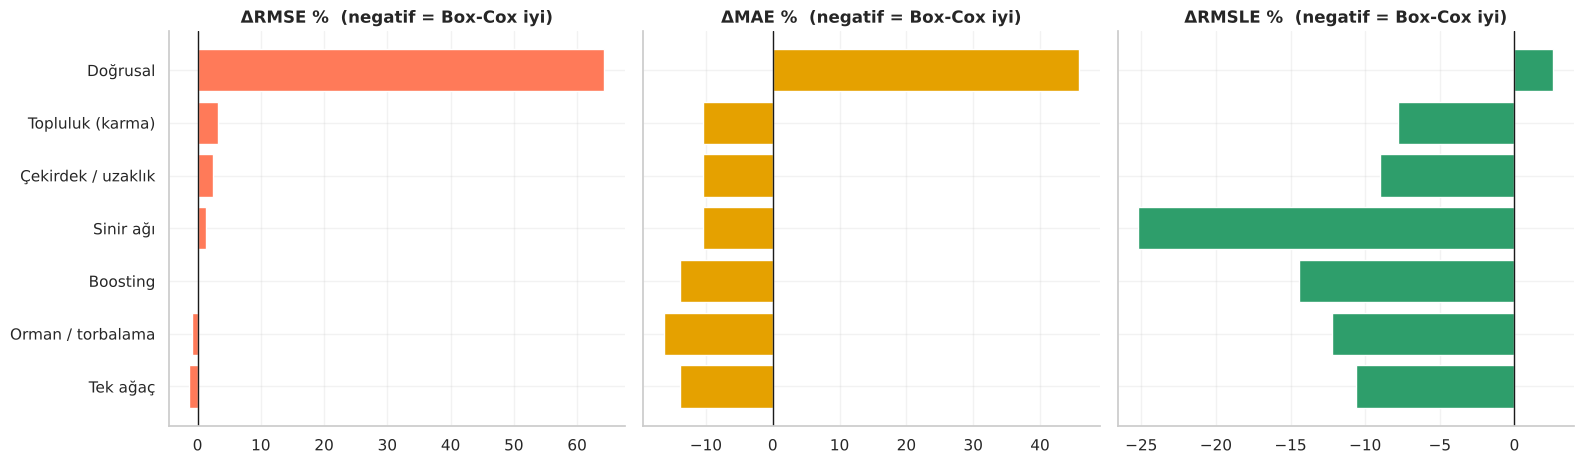

In [15]:
aile = {}
for a in ["Doğrusal regresyon", "Ridge", "Lasso", "ElasticNet", "Bayes Ridge", "Huber", "RANSAC", "SGD regresör", "Polinom(2) + Ridge"]: aile[a] = "Doğrusal"
for a in ["KNN", "SVR (RBF)", "Çekirdek Ridge (RBF)", "Gauss süreci"]: aile[a] = "Çekirdek / uzaklık"
aile["MLP"] = "Sinir ağı"
for a in ["Karar ağacı", "Extra tree (tek)"]: aile[a] = "Tek ağaç"
for a in ["Bagging (ağaç)", "Rastgele orman", "Extra trees"]: aile[a] = "Orman / torbalama"
for a in ["Gradient Boosting", "HistGradientBoosting", "AdaBoost", "XGBoost", "LightGBM", "CatBoost"]: aile[a] = "Boosting"
for a in ["Oylama (4 model)", "Yığın (Ridge meta)"]: aile[a] = "Topluluk (karma)"
bs["Aile"] = pd.Series(aile)
df_a = df.pivot(index="ad", columns="hedef", values=["RMSE", "RMSLE", "MAE"]).drop(index="Taban (ortalama)")
rel = pd.DataFrame({"Aile": pd.Series(aile), "ΔRMSE %": (df_a[("RMSE", "box-cox")] / df_a[("RMSE", "ham")] - 1) * 100,
                    "ΔMAE %": (df_a[("MAE", "box-cox")] / df_a[("MAE", "ham")] - 1) * 100,
                    "ΔRMSLE %": (df_a[("RMSLE", "box-cox")] / df_a[("RMSLE", "ham")] - 1) * 100}).dropna()
aile_ozet = rel.groupby("Aile")[["ΔRMSE %", "ΔMAE %", "ΔRMSLE %"]].median().round(1)
display(aile_ozet); rapor_kaydet(aile_ozet, "10_aile_ozeti")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for a, c, r in zip(ax, ["ΔRMSE %", "ΔMAE %", "ΔRMSLE %"], [RENK["mercan"], RENK["amber"], RENK["nane"]]):
    s = aile_ozet[c].sort_values(); a.barh(s.index, s.values, color=r); a.axvline(0, color="k", lw=1); a.set_title(c + "  (negatif = Box-Cox iyi)")
plt.tight_layout(); kaydet(fig, "06_aile_ozeti"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Genel örüntü (yukarıdaki tablo ve bootstrap'ten okunan):** Box-Cox hedef, **ağaç, boosting, orman, sinir ağı ve çekirdek ailelerinde MAE'yi %10–16 ve göreli hatayı (RMSLE) %8–25 düşürür**; dolar hatasında (RMSE) ise bu ailelerde fark **ayırt edilemez** düzeydedir (medyan ±%3). **Doğrusal ailede tablo tersine döner:** RMSE ve MAE belirgin **kötüleşir** (en çok doğrusal regresyon, Ridge, SGD gibi sade modeller). *Olası neden:* doğrusal bir model, `sigara × obez` gibi **toplamsal** dolar etkilerini ham hedefte yakalar; log benzeri uzayda aynı etkiler **çarpımsal** olur, doğrusal model onları kaçırır ve geri dönüşteki **üstel büyütme** hatayı şişirir. Bu bir hipotezdir, bu notebook onu doğrudan sınamıyor.

**Sonuç:** Dönüşüm bir **kural** değil, **ölçülerek verilecek bir karardır**; hangi ölçüt, hangi model ailesi sorusu cevabı belirler.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/proje_09.svg" width="100%" alt="Bölüm 9 · Dönüşüm × model">
</p>

### 🧪 9.1 · Altı Dönüşüm × Dokuz Model

Şimdiye dek iki senaryo vardı. Şimdi hedef için **altı** dönüşümü, farklı ailelerden **dokuz** modelde deniyoruz. Tüm hücreler aynı 5×2 katlarda, dolar dünyasında ölçülür.

📄 Rapor → outputs/reports/11_donusum_x_model.csv


💾 Kaydedildi → outputs/figures/08_donusum_x_model.png


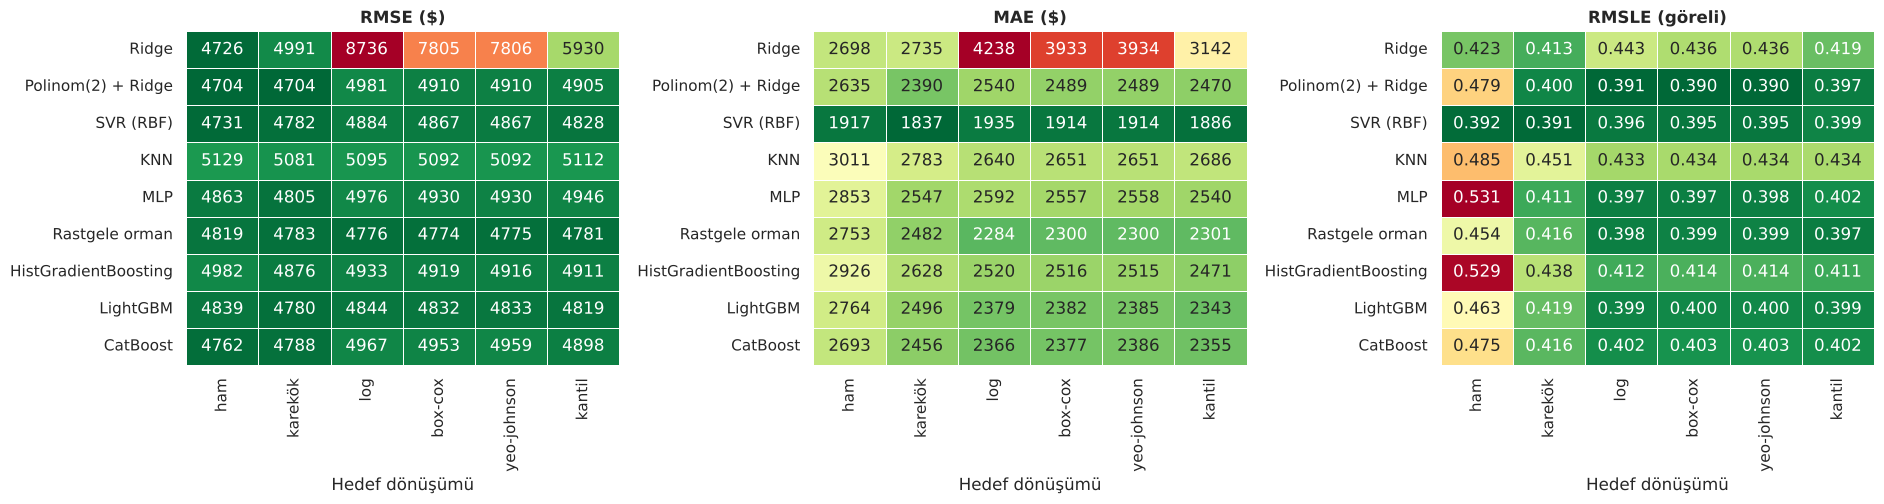

In [16]:
DON = ["ham", "karekök", "log", "box-cox", "yeo-johnson", "kantil"]
M9 = ["Ridge", "Polinom(2) + Ridge", "SVR (RBF)", "KNN", "MLP", "Rastgele orman", "HistGradientBoosting", "LightGBM", "CatBoost"]
isler = [delayed(kos)(a, tum_modeller[a][0], tum_modeller[a][1], h, ek=EK_KALSIN, oof_tur=0) for a in M9 for h in DON]
r9 = pd.DataFrame(Parallel(n_jobs=N_IS)(isler))
rapor_kaydet(r9.drop(columns="oof"), "11_donusum_x_model", index=False)

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for a, (c, baslik) in zip(ax, [("RMSE", "RMSE ($)"), ("MAE", "MAE ($)"), ("RMSLE", "RMSLE (göreli)")]):
    p = r9.pivot(index="ad", columns="hedef", values=c).loc[M9, DON]
    sns.heatmap(p, annot=True, fmt=".0f" if c != "RMSLE" else ".3f", cmap="RdYlGn_r", ax=a, cbar=False, linewidths=.5)
    a.set_title(baslik); a.set_xlabel("Hedef dönüşümü"); a.set_ylabel("")
plt.tight_layout(); kaydet(fig, "08_donusum_x_model"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Tablodan üç gözlem: **(1)** `log`, `Box-Cox` ve `Yeo-Johnson` neredeyse **aynı** sonucu verir (λ ≈ 0,05 zaten log'a çok yakın). **(2)** Güçlü sıkıştırma (log/Box-Cox/Yeo-Johnson) MAE'yi çoğu modelde düşürür ama doğrusal modellerde RMSE'yi bozar. **(3)** **Karekök (λ = 0,5)**, çoğu modelde iki uç arasında **dengeli** durur: LightGBM, MLP ve KNN'de en düşük RMSE'ye sahiptir; SVR'de en düşük MAE'ye. **Kantil** çana en çok benzeyen hedefi üretir; ters dönüşümde ise **eğitimdeki aralığın dışına çıkamaz** (bu bir tasarım sınırıdır). Bu veride kantilin ek bir üstünlüğü görülmedi.

</td></tr></table>

### 🎛️ 9.2 · λ Düğmesini Çevirerek Skor Okumak

Box-Cox'un asıl gücü **λ düğmesi**dir. λ = 1 «hiç dönüşüm yok» (kontrol), λ = 0 logaritma, λ < 0 ise çok güçlü sıkıştırmadır. Düğmeyi **−0,4'ten 1'e** tarıyoruz; sabit λ'lı dönüşümü bu tarama için `SabitGuc` sınıfı sağlar. Üç farklı model, **üç ölçüt**: dolar hatası, ortalama dolar hatası, göreli hata.

In [17]:
LAMS = [round(x, 1) for x in np.arange(-0.4, 1.01, 0.1)]
M3 = ["Ridge", "SVR (RBF)", "LightGBM"]
isler = [delayed(kos)(a, tum_modeller[a][0], tum_modeller[a][1], l, ek=EK_KALSIN, oof_tur=0) for a in M3 for l in LAMS]
rl = pd.DataFrame(Parallel(n_jobs=N_IS)(isler)); rl["lam"] = rl["hedef"].str.replace("λ=", "").astype(float)
rapor_kaydet(rl.drop(columns=["oof", "hedef"]), "12_lambda_taramasi", index=False)

for a in M3:
    s = rl[rl.ad == a].set_index("lam")
    print(f"{a:10s} → en iyi λ: RMSE için {s.RMSE.idxmin():+.1f} | MAE için {s.MAE.idxmin():+.1f} | RMSLE için {s.RMSLE.idxmin():+.1f}")

📄 Rapor → outputs/reports/12_lambda_taramasi.csv
Ridge      → en iyi λ: RMSE için +0.9 | MAE için +0.8 | RMSLE için +0.5
SVR (RBF)  → en iyi λ: RMSE için +1.0 | MAE için +0.5 | RMSLE için +0.8
LightGBM   → en iyi λ: RMSE için +0.5 | MAE için -0.2 | RMSLE için -0.3


🎞️ Animasyon → outputs/figures/09_lambda_dugmesi.gif


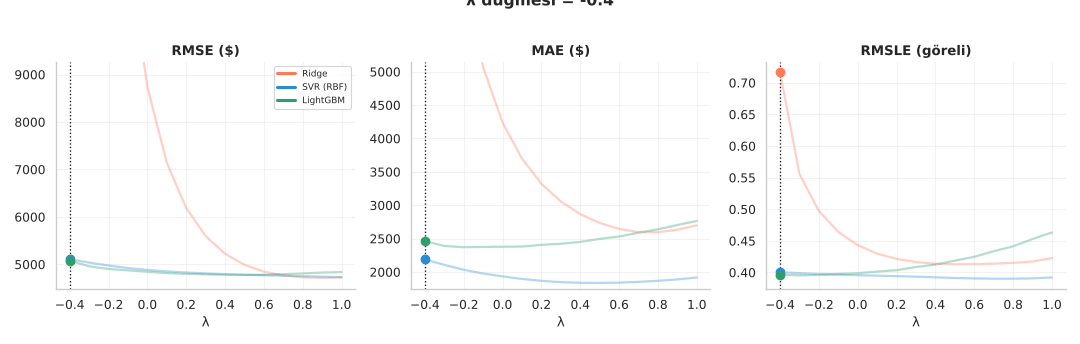

In [18]:
# ── Animasyon: λ düğmesi dönerken üç ölçüt ──────────────────
renk3 = {"Ridge": RENK["mercan"], "SVR (RBF)": RENK["gok"], "LightGBM": RENK["nane"]}
gif_lam = LAMS + [LAMS[-1]] * 3

def kare_dugme(i, fig):
    l = gif_lam[i]
    for j, (c, baslik) in enumerate([("RMSE", "RMSE ($)"), ("MAE", "MAE ($)"), ("RMSLE", "RMSLE (göreli)")]):
        a = fig.add_subplot(1, 3, j + 1)
        for m in M3:
            s = rl[rl.ad == m].sort_values("lam")
            a.plot(s.lam, s[c], color=renk3[m], lw=2, alpha=.35)
            u = s[s.lam <= l + 1e-9]
            a.plot(u.lam, u[c], color=renk3[m], lw=2.8, label=m if j == 0 else None)
            a.scatter([u.lam.iloc[-1]], [u[c].iloc[-1]], color=renk3[m], s=60, zorder=4)
        a.axvline(l, color="k", ls=":", lw=1.2); a.set_title(baslik); a.set_xlabel("λ")
        if c == "RMSE": a.set_ylim(rl.RMSE.min() * .95, min(rl.RMSE.max(), 9000) * 1.03)
        if c == "MAE": a.set_ylim(rl.MAE.min() * .95, min(rl.MAE.max(), 5000) * 1.03)
    fig.axes[0].legend(fontsize=8, loc="upper right"); fig.suptitle(f"λ düğmesi = {l:+.1f}", fontsize=14, fontweight="bold", y=1.02)

gif_kaydet(kare_dugme, len(gif_lam), "09_lambda_dugmesi", figsize=(13.5, 4.3), fps=3)

💾 Kaydedildi → outputs/figures/10_lambda_egrileri.png


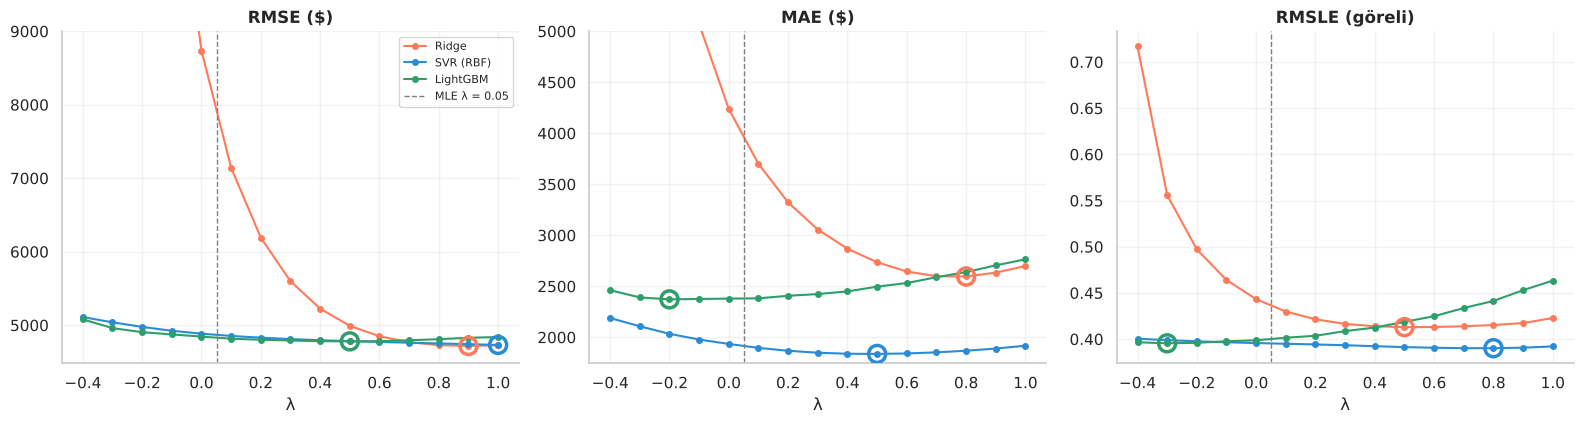

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, (c, baslik) in zip(ax, [("RMSE", "RMSE ($)"), ("MAE", "MAE ($)"), ("RMSLE", "RMSLE (göreli)")]):
    for m in M3:
        s = rl[rl.ad == m].sort_values("lam"); a.plot(s.lam, s[c], marker="o", ms=4, color=renk3[m], label=m)
        a.scatter([s.lam[s[c].idxmin()]], [s[c].min()], s=150, facecolors="none", edgecolors=renk3[m], lw=2.5, zorder=5)
    a.axvline(lam_bc, color="gray", ls="--", lw=1, label=f"MLE λ = {lam_bc:.2f}"); a.set_title(baslik); a.set_xlabel("λ")
    if c == "RMSE": a.set_ylim(rl.RMSE.min() * .95, min(rl.RMSE.max(), 9000))
    if c == "MAE": a.set_ylim(rl.MAE.min() * .95, min(rl.MAE.max(), 5000))
ax[0].legend(fontsize=8); plt.tight_layout(); kaydet(fig, "10_lambda_egrileri"); plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Üç ölçüt, üç farklı «en iyi λ»; ve hiçbiri veri-çana-benzer λ'da değil.** Dairelerle işaretlenen en iyi noktalar ölçüte ve modele göre kayar: Ridge ve SVR'de **dolar hatası** (RMSE) en iyi λ ≈ 0,9–1,0 (yani **hiç dönüşüm yok**), göreli hata (RMSLE) için λ ≈ 0,5–0,8. LightGBM'de ise MAE ve RMSLE için en iyi λ **negatif** (−0,2/−0,3), RMSE için 0,5. Çana en çok benzeyen nokta (MLE λ ≈ 0,05) **hiçbir model-ölçüt çiftinin optimumu değil**. Veri çana en çok benzediği λ'da değil, **ölçütünüzün** en iyi olduğu λ'da durmalısınız: çana benzerlik **bir hedef değil, bir araçtır.**

</td></tr></table>

### 🧰 9.3 · Özellik Tarafında Yeo-Johnson: Ölçeğe Duyarlı Modellerde

Hedefi bir kenara bırakıp **özellikleri** Yeo-Johnson ile dönüştürmenin (standartlaştırma yerine) ölçeğe duyarlı beş modeldeki etkisine bakıyoruz.

In [20]:
M5 = ["Ridge", "Polinom(2) + Ridge", "SVR (RBF)", "KNN", "MLP"]
isler = [delayed(kos)(a, tum_modeller[a][0], tum_modeller[a][1], h, ek=EK_KALSIN, yj=yj, oof_tur=0) for a in M5 for h in ("ham", "box-cox") for yj in (False, True)]
ry = pd.DataFrame(Parallel(n_jobs=N_IS)(isler)); ry["Özellik ölçekleme"] = np.where(ry["yj"], "Yeo-Johnson", "Standart")
tab = ry.pivot_table(index="ad", columns=["hedef", "Özellik ölçekleme"], values=["RMSE", "RMSLE"]).loc[M5]
display(tab.round(3)); rapor_kaydet(tab, "13_ozellik_yeojohnson")
fark = {}
for h in ("ham", "box-cox"):
    for c in ("RMSE", "RMSLE"):
        fark[f"{c} · {h}: Yeo-Johnson − Standart (%)"] = ((tab[(c, h, "Yeo-Johnson")] / tab[(c, h, "Standart")] - 1) * 100).round(2)
display(pd.DataFrame(fark))

RMSE                                      RMSLE  \
hedef                box-cox                   ham              box-cox   
Özellik ölçekleme   Standart Yeo-Johnson  Standart Yeo-Johnson Standart   
ad                                                                        
Ridge               7805.116    7612.667  4725.766    4769.989    0.436   
Polinom(2) + Ridge  4910.063    4934.913  4703.839    4696.912    0.390   
SVR (RBF)           4866.845    4858.892  4731.228    4730.092    0.395   
KNN                 5091.678    5109.031  5128.744    5135.369    0.434   
MLP                 4930.093    4931.908  4862.522    4847.085    0.397   

                                                     
hedef                               ham              
Özellik ölçekleme  Yeo-Johnson Standart Yeo-Johnson  
ad                                                   
Ridge                    0.435    0.423       0.438  
Polinom(2) + Ridge       0.389    0.479       0.478  
SVR (RBF)                0.394    0.392       0.395  
KNN                      0.437    0.485       0.487  
MLP                      0.395    0.531       0.542

📄 Rapor → outputs/reports/13_ozellik_yeojohnson.csv


,RMSE · ham: Yeo-Johnson − Standart (%),RMSLE · ham: Yeo-Johnson − Standart (%),RMSE · box-cox: Yeo-Johnson − Standart (%),RMSLE · box-cox: Yeo-Johnson − Standart (%)
ad,,,,
Ridge,0.94,3.66,-2.47,-0.11
Polinom(2) + Ridge,-0.15,-0.06,0.51,-0.42
SVR (RBF),-0.02,0.64,-0.16,-0.38
KNN,0.13,0.41,0.34,0.61
MLP,-0.32,1.99,0.04,-0.64


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Özellik tarafında Yeo-Johnson, standartlaştırmaya göre **çoğunlukla ±%1 içinde** bir fark yaratır; tek belirgin değişim **Ridge + Box-Cox hedef** çiftinde (RMSE ≈ %2,5 düşüş) ama o çiftin hatası zaten çok yüksek. `age` ve `bmi` hemen hemen simetrik olduğu için beklenen budur: **özellik dönüşümü, hedef dönüşümünden çok daha küçük bir kaldıraçtır.**

</td></tr></table>

### ↩️ 9.4 · Ters Dönüşüm Yanlılığı ve Smearing

Kavram dersinde ters dönüşümün **ortalamayı değil ortancayı** verdiğini görmüştük. Şimdi gerçek modelde ölçüyoruz: tahminlerin ortalaması, gerçek ortalamadan ne kadar sapıyor? **Smearing** (Duan, 1983) bu sapmayı, dönüşmüş uzaydaki **artıkların** tahmine eklenip ters dönüştürülmesiyle düzeltmeyi dener.

In [21]:
def oof_ver(model, katlar=KATLAR, tur=5):
    oof = np.full(len(ytr), np.nan)
    for k, (a, b) in enumerate(katlar[:tur]):
        oof[b] = clone(model).fit(Xtr.iloc[a], ytr[a]).predict(Xtr.iloc[b])
    return oof

def govde(olcek):
    return [sy.OzellikUretici(ek=EK_KALSIN)] + ([StandardScaler()] if olcek else [])

satir = []
for ad in ["Ridge", "SVR (RBF)", "LightGBM"]:
    e, o = tum_modeller[ad]
    taban = make_pipeline(*govde(o), clone(e))
    varyant = {"A · ham": OOF[(ad, "ham")],
               "B · Box-Cox (düz ters dönüşüm)": OOF[(ad, "box-cox")],
               "C · Box-Cox + smearing": oof_ver(sy.BoxCoxSmearing(model=taban, duzelt=True))}
    for ad_v, p in varyant.items():
        d = olc(ytr, p); d.update(model=ad, senaryo=ad_v, **{"Ortalama sapma %": (p.mean() / ytr.mean() - 1) * 100}); satir.append(d)
sm = pd.DataFrame(satir).set_index(["model", "senaryo"])[["RMSE", "MAE", "RMSLE", "Ortalama sapma %"]]
display(sm.round(3)); rapor_kaydet(sm, "14_smearing")

RMSE       MAE  RMSLE  \
model     senaryo                                                     
Ridge     A · ham                         4758.838  2695.453  0.427   
          B · Box-Cox (düz ters dönüşüm)  7880.909  3938.665  0.438   
          C · Box-Cox + smearing          9033.596  4812.997  0.460   
SVR (RBF) A · ham                         4762.009  1908.669  0.396   
          B · Box-Cox (düz ters dönüşüm)  4883.637  1903.572  0.400   
          C · Box-Cox + smearing          5357.525  3526.009  0.403   
LightGBM  A · ham                         4852.541  2741.469  0.469   
          B · Box-Cox (düz ters dönüşüm)  4852.012  2378.873  0.405   
          C · Box-Cox + smearing          4972.198  3167.747  0.420   

                                          Ortalama sapma %  
model     senaryo                                           
Ridge     A · ham                                   -0.093  
          B · Box-Cox (düz ters dönüşüm)            -1.495  
          C · Box-Cox + smearing                    10.848  
SVR (RBF) A · ham                                   -7.718  
          B · Box-Cox (düz ters dönüşüm)            -9.465  
          C · Box-Cox + smearing                     8.724  
LightGBM  A · ham                                   -0.307  
          B · Box-Cox (düz ters dönüşüm)            -5.145  
          C · Box-Cox + smearing                     4.992

📄 Rapor → outputs/reports/14_smearing.csv


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

«Ortalama sapma %» sütunu, tahminlerin **toplamının** gerçeğe oranını söyler. Düz ters dönüşümde LightGBM'in toplamı **%5, SVR'ninki %9 düşük** kalır (ortanca etkisi). Smearing toplamı **hizalar ama aşırı düzeltir** (+%5…+%11) ve **RMSE ile MAE'yi kötüleştirir**. *Olası neden:* ortak artık havuzu, düşük masraflı (sigara içmeyen) kitlenin **dar** yayılımını, yüksek masraflı kitlenin **geniş** yayılımına göre şişirir; sabit yayılım varsayımı bu veride geçmez. Sonuç: **toplam bütçeyi** tahmin ediyorsanız bu yanlılığı bilin; **tek tek isabet** istiyorsanız düz ters dönüşüm daha iyi kalır.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/proje_10.svg" width="100%" alt="Bölüm 10 · Hiperparametre ayarı">
</p>

### 🎛️ 10.1 · Hedef Dönüşümü de Bir Hiperparametredir

Dört güçlü aday (**LightGBM, XGBoost, CatBoost, SVR**) için **rastgele arama** yapıyoruz (40 deneme × 5 kat). Arama uzayına, modelin düğmelerinin yanına **hedef dönüşümünü** de ekliyoruz: `ham`, `λ = 0,75`, `λ = 0,5`, `λ = 0,25`, `Box-Cox (MLE)`. Ayrıca her model için **yalnızca ham hedefli** bir arama yapıyoruz; böylece «**Box-Cox'a izin vermek** ayarlı modelde bir şey kazandırıyor mu?» sorusuna cevap alıyoruz.

> **Seçim kuralı (sonuçlardan önce yazıldı):** Final model, **taze katlarda** (farklı tohum) **en düşük ortalama RMSE**'ye sahip ayarlı adaydır. Fark %1'den küçükse ikinci ölçüt MAE, hâlâ yakınsa **daha sade** (daha az parametreli) model seçilir. Test seti seçime **karışmaz**.

In [22]:
from scipy.stats import loguniform, randint, uniform

DON_SEC = [sy.hedef_donusturucu("ham"), sy.hedef_donusturucu(0.75), sy.hedef_donusturucu(0.5), sy.hedef_donusturucu(0.25), sy.hedef_donusturucu("box-cox")]
def don_etiket(t):
    if isinstance(t, sy.SabitGuc): return f"λ={t.lam:g}"
    if isinstance(t, PowerTransformer): return "Box-Cox (MLE)"
    return "ham"

UZAY = {
    "LightGBM": dict(num_leaves=randint(4, 32), learning_rate=loguniform(0.01, 0.15), n_estimators=randint(100, 600), min_child_samples=randint(5, 60),
                     subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.6, 0.4), reg_lambda=loguniform(1e-2, 30)),
    "XGBoost": dict(max_depth=randint(2, 6), learning_rate=loguniform(0.01, 0.15), n_estimators=randint(100, 600), subsample=uniform(0.6, 0.4),
                    colsample_bytree=uniform(0.6, 0.4), min_child_weight=randint(1, 20), reg_lambda=loguniform(1e-2, 30)),
    "CatBoost": dict(depth=randint(3, 7), learning_rate=loguniform(0.02, 0.15), iterations=randint(200, 700), l2_leaf_reg=loguniform(1, 20)),
    "SVR (RBF)": dict(C=loguniform(0.3, 100), epsilon=loguniform(1e-3, 0.3), gamma=loguniform(1e-3, 0.5)),
}
CV_ARAMA = KFold(5, shuffle=True, random_state=11)

def ara(ad, don_serbest):
    e, o = tum_modeller[ad]
    tt = sy.boru_hatti(ad, e, o, ek=EK_KALSIN, hedef="box-cox")
    son = tt.regressor.steps[-1][0]
    uzay = {f"regressor__{son}__{k}": v for k, v in UZAY[ad].items()}
    uzay["transformer"] = DON_SEC if don_serbest else [sy.hedef_donusturucu("ham")]
    if not don_serbest: tt.set_params(transformer=sy.hedef_donusturucu("ham"))
    rs_ = RandomizedSearchCV(tt, uzay, n_iter=40, cv=CV_ARAMA, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=N_IS, refit=True)
    t0 = time.time(); rs_.fit(Xtr, ytr)
    return ad, don_serbest, rs_, time.time() - t0

t0 = time.time()
arama = {}
for ad in UZAY:
    for ds in (False, True):
        _, _, r_, sn = ara(ad, ds); arama[(ad, ds)] = r_
        print(f"{ad:10s} | dönüşüm serbest: {str(ds):5s} | arama CV RMSE = {-r_.best_score_:7.1f} | seçilen dönüşüm: {don_etiket(r_.best_params_['transformer']):14s} | {sn:5.1f} sn")
print(f"Toplam arama süresi: {time.time() - t0:.0f} sn")

LightGBM   | dönüşüm serbest: False | arama CV RMSE =  4786.8 | seçilen dönüşüm: ham            |   3.0 sn


LightGBM   | dönüşüm serbest: True  | arama CV RMSE =  4760.9 | seçilen dönüşüm: λ=0.75         |   2.9 sn


XGBoost    | dönüşüm serbest: False | arama CV RMSE =  4715.8 | seçilen dönüşüm: ham            |   3.1 sn


XGBoost    | dönüşüm serbest: True  | arama CV RMSE =  4697.4 | seçilen dönüşüm: λ=0.5          |   3.4 sn


CatBoost   | dönüşüm serbest: False | arama CV RMSE =  4702.9 | seçilen dönüşüm: ham            |   6.0 sn


CatBoost   | dönüşüm serbest: True  | arama CV RMSE =  4699.9 | seçilen dönüşüm: λ=0.75         |   5.4 sn


SVR (RBF)  | dönüşüm serbest: False | arama CV RMSE =  4618.2 | seçilen dönüşüm: ham            |   3.6 sn


SVR (RBF)  | dönüşüm serbest: True  | arama CV RMSE =  4637.3 | seçilen dönüşüm: ham            |   5.2 sn
Toplam arama süresi: 33 sn


### 🆕 10.2 · Taze Katlarda Doğrulama ve Seçim Kuralının Uygulanması

Aramanın kendi skoru **iyimserdir** (en iyi seçim ona göre yapıldı). Bu yüzden her adayı **taze katlarda** (seçimde kullanılmamış bir bölme) yeniden değerlendiriyoruz ve **önceden yazılmış kuralı** uyguluyoruz.

In [23]:
def kos_model(ad, model, katlar=KATLAR_TAZE):
    olc_ = []
    for a, b in katlar:
        p = clone(model).fit(Xtr.iloc[a], ytr[a]).predict(Xtr.iloc[b]); olc_.append(olc(ytr[b], p))
    d = pd.DataFrame(olc_).mean().to_dict(); d["ad"] = ad; return d

adaylar_son = {}
for ad in UZAY:
    e, o = tum_modeller[ad]
    adaylar_son[f"{ad} · varsayılan · ham"] = sy.boru_hatti(ad, e, o, ek=EK_KALSIN, hedef="ham")
    adaylar_son[f"{ad} · varsayılan · Box-Cox"] = sy.boru_hatti(ad, e, o, ek=EK_KALSIN, hedef="box-cox")
    adaylar_son[f"{ad} · ayarlı · yalnız ham"] = arama[(ad, False)].best_estimator_
    adaylar_son[f"{ad} · ayarlı · dönüşüm serbest ({don_etiket(arama[(ad, True)].best_params_['transformer'])})"] = arama[(ad, True)].best_estimator_
sonuc_taze = pd.DataFrame(Parallel(n_jobs=N_IS)(delayed(kos_model)(a, m) for a, m in adaylar_son.items())).set_index("ad")
display(sonuc_taze.round(3).style.background_gradient(subset=["RMSE"], cmap="RdYlGn_r")); rapor_kaydet(sonuc_taze, "15_ayar_taze_katlar")

# ── Seçim kuralı (önceden yazıldı): ayarlı adaylar arasında en düşük taze RMSE; fark < %1 ise MAE; sonra sade model ──
ayarli = sonuc_taze[sonuc_taze.index.str.contains("ayarlı")].sort_values("RMSE")
en = ayarli.iloc[0]
yakin = ayarli[ayarli.RMSE <= en.RMSE * 1.01].sort_values("MAE")
SECILEN = yakin.index[0]
print("Kurala göre en düşük RMSE:", ayarli.index[0], f"({en.RMSE:.1f})")
if len(yakin) > 1: print("RMSE farkı <%1 olanlar MAE'ye göre sıralandı →", list(yakin.index))
print("\n✅ SEÇİLEN FİNAL ADAY:", SECILEN)
FINAL = adaylar_son[SECILEN]
display(Markdown(f"**Final model:** `{SECILEN}`"))

,RMSE,MAE,R2,RMSLE
ad,,,,
LightGBM · varsayılan · ham,4876.508000,2764.406000,0.833000,0.463000
LightGBM · varsayılan · Box-Cox,4865.676000,2385.162000,0.835000,0.400000
LightGBM · ayarlı · yalnız ham,4785.267000,2754.762000,0.840000,0.442000
LightGBM · ayarlı · dönüşüm serbest (λ=0.75),4783.011000,2563.437000,0.840000,0.422000
XGBoost · varsayılan · ham,4849.872000,2768.499000,0.836000,0.460000
XGBoost · varsayılan · Box-Cox,4854.458000,2326.795000,0.835000,0.397000
XGBoost · ayarlı · yalnız ham,4725.973000,2689.338000,0.844000,0.444000
XGBoost · ayarlı · dönüşüm serbest (λ=0.5),4732.792000,2358.666000,0.843000,0.407000
CatBoost · varsayılan · ham,4829.904000,2721.954000,0.837000,0.453000


📄 Rapor → outputs/reports/15_ayar_taze_katlar.csv
Kurala göre en düşük RMSE: SVR (RBF) · ayarlı · yalnız ham (4642.9)
RMSE farkı <%1 olanlar MAE'ye göre sıralandı → ['SVR (RBF) · ayarlı · dönüşüm serbest (ham)', 'SVR (RBF) · ayarlı · yalnız ham']

✅ SEÇİLEN FİNAL ADAY: SVR (RBF) · ayarlı · dönüşüm serbest (ham)


**Final model:** `SVR (RBF) · ayarlı · dönüşüm serbest (ham)`

In [24]:
fark_ham_bc = {ad: (sonuc_taze.loc[f"{ad} · ayarlı · yalnız ham", "RMSE"], sonuc_taze.loc[[i for i in sonuc_taze.index if i.startswith(f"{ad} · ayarlı · dönüşüm serbest")][0], "RMSE"]) for ad in UZAY}
for ad, (h_, s_) in fark_ham_bc.items(): print(f"{ad:10s} ayarlı: yalnız ham {h_:7.1f} | dönüşüm serbest {s_:7.1f} | fark {(s_ / h_ - 1) * 100:+.2f}%")
display(Markdown("**Okuma:** Dönüşümün serbest bırakılması ayarlı modellerde RMSE'yi **%1'in altında** oynatıyor (hepsi ayırt edilemez düzeyde); fakat **MAE** ağaç modellerinde belirgin düşüyor (örn. LightGBM 2.755 → 2.563). Kural dolar hatasını (RMSE) ana ölçüt saydığı için **SVR + ham hedef** seçildi; yani **bu veride ayarlı en iyi model için Box-Cox gerekmedi.** Bu, 7. bölümdeki «dönüşüm herkese yaramaz» bulgusuyla tutarlı."))

LightGBM   ayarlı: yalnız ham  4785.3 | dönüşüm serbest  4783.0 | fark -0.05%
XGBoost    ayarlı: yalnız ham  4726.0 | dönüşüm serbest  4732.8 | fark +0.14%
CatBoost   ayarlı: yalnız ham  4725.4 | dönüşüm serbest  4737.3 | fark +0.25%
SVR (RBF)  ayarlı: yalnız ham  4642.9 | dönüşüm serbest  4664.4 | fark +0.46%


**Okuma:** Dönüşümün serbest bırakılması ayarlı modellerde RMSE'yi **%1'in altında** oynatıyor (hepsi ayırt edilemez düzeyde); fakat **MAE** ağaç modellerinde belirgin düşüyor (örn. LightGBM 2.755 → 2.563). Kural dolar hatasını (RMSE) ana ölçüt saydığı için **SVR + ham hedef** seçildi; yani **bu veride ayarlı en iyi model için Box-Cox gerekmedi.** Bu, 7. bölümdeki «dönüşüm herkese yaramaz» bulgusuyla tutarlı.

💾 Kaydedildi → outputs/figures/11_ayar_taze_katlar.png


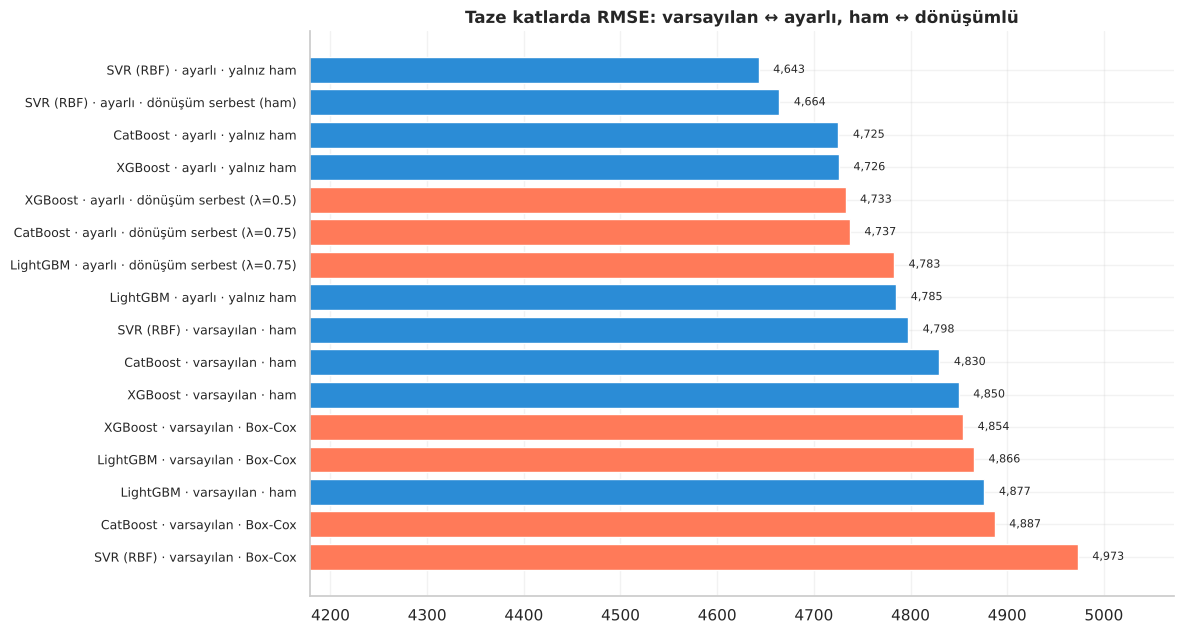

In [25]:
fig, ax = plt.subplots(figsize=(12, 6.5))
s = sonuc_taze.sort_values("RMSE", ascending=False); y = np.arange(len(s))
renk = [RENK["mercan"] if "Box-Cox" in i or "λ=" in i or "MLE" in i else RENK["gok"] for i in s.index]
ax.barh(y, s.RMSE, color=renk); ax.set_yticks(y); ax.set_yticklabels(s.index, fontsize=9); ax.set_xlim(s.RMSE.min() * .9, s.RMSE.max() * 1.02)
for i, v in enumerate(s.RMSE): ax.text(v + 15, i, f"{v:,.0f}", va="center", fontsize=8)
ax.set_title("Taze katlarda RMSE: varsayılan ↔ ayarlı, ham ↔ dönüşümlü"); plt.tight_layout(); kaydet(fig, "11_ayar_taze_katlar"); plt.show()

<a id="p11"></a>

<p align="center">
  <img src="assets/proje_11.svg" width="100%" alt="Bölüm 11 · Önem ve ablasyon">
</p>

### 🔍 11.1 · Permütasyon Önemi: Sütunu Karıştırınca Skor Ne Kadar Düşüyor?

Final modeli eğitimin %75'inde eğitip kalan %25'te (**test değil**) ölçüyoruz; her ham sütunu 30 kez karıştırıp dolar hatasındaki artışa bakıyoruz.

,ort. RMSE artışı ($),std
smoker,10778.8,642.6
bmi,3499.2,364.4
age,2580.1,190.3
children,163.6,39.6
region,38.6,16.7
sex,-5.6,16.9


📄 Rapor → outputs/reports/16_permutasyon_onemi.csv
💾 Kaydedildi → outputs/figures/12_permutasyon_onemi.png


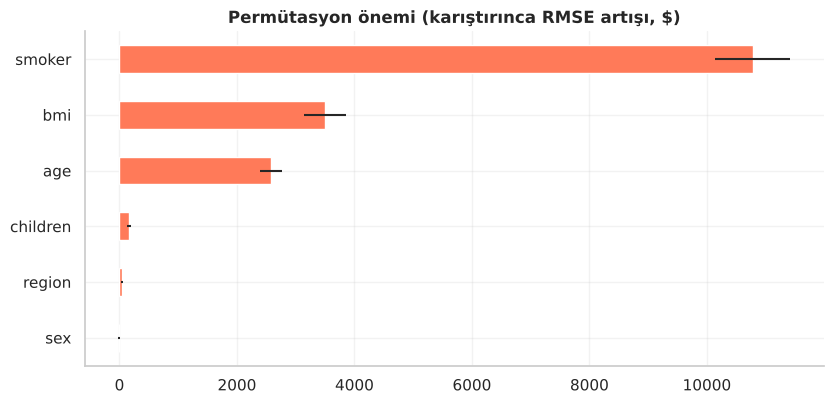

In [26]:
tr2, va2 = train_test_split(np.arange(len(Xtr)), test_size=0.25, stratify=Xtr["smoker"], random_state=3)
m_imp = clone(FINAL).fit(Xtr.iloc[tr2], ytr[tr2])
pi = permutation_importance(m_imp, Xtr.iloc[va2], ytr[va2], scoring="neg_root_mean_squared_error", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.DataFrame({"ort. RMSE artışı ($)": pi.importances_mean, "std": pi.importances_std}, index=Xtr.columns).sort_values("ort. RMSE artışı ($)", ascending=False)
display(imp.round(1)); rapor_kaydet(imp, "16_permutasyon_onemi")
fig, ax = plt.subplots(figsize=(8.5, 4.2)); imp["ort. RMSE artışı ($)"][::-1].plot.barh(xerr=imp["std"][::-1], color=RENK["mercan"], ax=ax)
ax.set_title("Permütasyon önemi (karıştırınca RMSE artışı, $)"); plt.tight_layout(); kaydet(fig, "12_permutasyon_onemi"); plt.show()

### 🌲 11.2 · TreeSHAP: Her Kişi İçin Katkılar

TreeSHAP, her kişinin tahminini **sütun katkılarına** böler. Ağaç tabanlı en iyi aday olarak **ayarlı LightGBM** kullanıyoruz (Box-Cox hedefle). SHAP katkıları **dönüşmüş (çanımsı) uzayda** toplanır: bu uzayda toplanan katkılar, dolar dünyasında **çarpımsal** etkilere denk gelir (örneğin «sigara içmek primi kat kat artırır»).

💾 Kaydedildi → outputs/figures/13_shap_ozeti.png


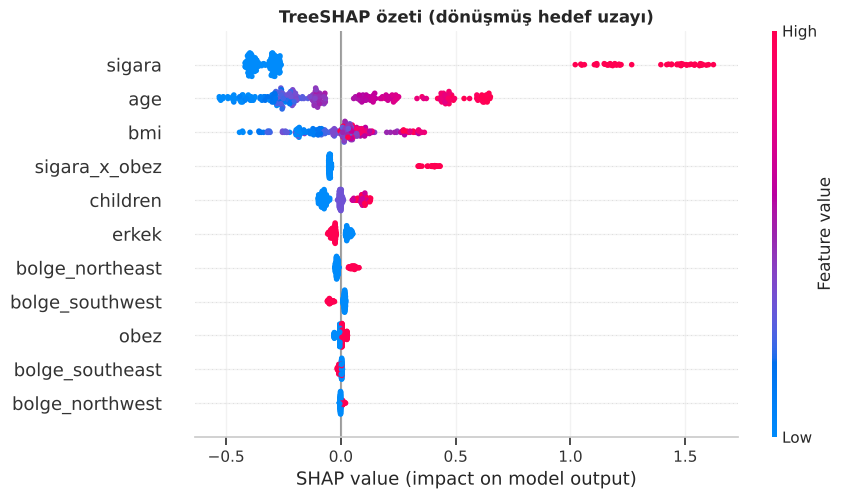

,sigara,age,bmi,sigara_x_obez,children,erkek,bolge_northeast,bolge_southwest,obez,bolge_southeast,bolge_northwest
ort. |SHAP|,0.546,0.296,0.117,0.088,0.063,0.033,0.025,0.022,0.009,0.004,0.004


In [27]:
import shap
lgb_adayi = arama[("LightGBM", True)].best_estimator_
m_shap = clone(lgb_adayi).fit(Xtr.iloc[tr2], ytr[tr2])
ozellikler = m_shap.regressor_[:-1].transform(Xtr.iloc[va2])
expl = shap.TreeExplainer(m_shap.regressor_[-1]); sv = expl.shap_values(ozellikler)
shap.summary_plot(sv, ozellikler, show=False, plot_size=(9, 5)); plt.title("TreeSHAP özeti (dönüşmüş hedef uzayı)")
kaydet(plt.gcf(), "13_shap_ozeti"); plt.show()
ort_shap = pd.Series(np.abs(sv).mean(0), index=ozellikler.columns).sort_values(ascending=False)
display(ort_shap.round(3).to_frame("ort. |SHAP|").T)

### 🧱 11.3 · Ablasyon: Bilgiyi Gerçekten Çıkarıp Ölçmek

Önem ölçüleri **dolaylıdır**. Ablasyon bir sütunu **sabit bir değerle** değiştirip (bilgiyi öldürüp) final modelin taze katlardaki skorunu yeniden ölçer. `sex + region` satırı, **etik açıdan sorunlu olabilecek sütunları** çıkarmanın maliyetini gösterir.

,RMSE,MAE,RMSLE,R2,RMSE değişimi %
Hiçbiri (tam model),4664.363,2142.188,0.391,0.848,0.000
smoker,12766.401,6835.062,0.817,-0.117,173.701
bmi,7062.659,3815.998,0.431,0.656,51.417
age,6181.864,4436.493,0.678,0.734,32.534
children,4821.908,2030.756,0.413,0.838,3.378
sex,4697.803,1999.432,0.390,0.846,0.717
region,4695.465,2006.080,0.392,0.846,0.667
sex + region,4739.743,1889.041,0.396,0.843,1.616


📄 Rapor → outputs/reports/17_ablasyon.csv
💾 Kaydedildi → outputs/figures/14_ablasyon.png


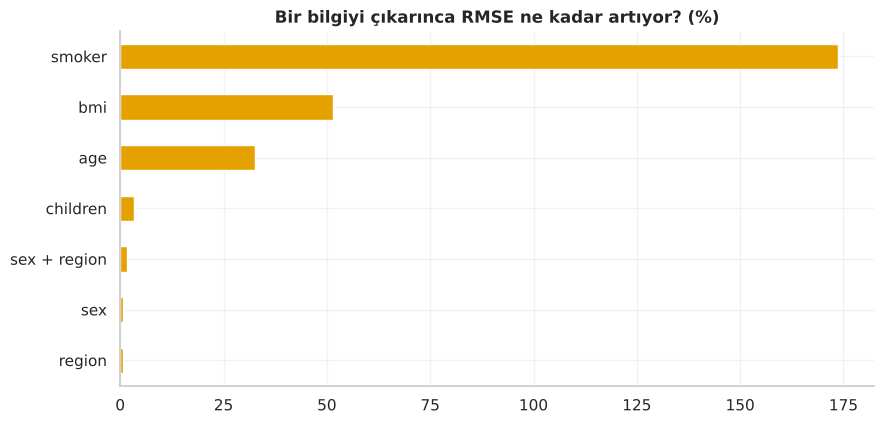

In [28]:
grup_ab = {"Hiçbiri (tam model)": [], "smoker": ["smoker"], "bmi": ["bmi"], "age": ["age"], "children": ["children"], "sex": ["sex"], "region": ["region"], "sex + region": ["sex", "region"]}
def ablasyon(sutunlar):
    mm = TransformedTargetRegressor(regressor=make_pipeline(sy.KolonKapat(sutunlar=tuple(sutunlar)), clone(FINAL.regressor)), transformer=clone(FINAL.transformer), check_inverse=False)
    return kos_model(",".join(sutunlar) or "tam", mm)
ab = pd.DataFrame(Parallel(n_jobs=N_IS)(delayed(ablasyon)(c) for c in grup_ab.values()), index=list(grup_ab))[["RMSE", "MAE", "RMSLE", "R2"]]
ab["RMSE değişimi %"] = (ab.RMSE / ab.loc["Hiçbiri (tam model)", "RMSE"] - 1) * 100
display(ab.round(3)); rapor_kaydet(ab, "17_ablasyon")
fig, ax = plt.subplots(figsize=(9, 4.4)); ab["RMSE değişimi %"].drop("Hiçbiri (tam model)").sort_values().plot.barh(color=RENK["amber"], ax=ax)
ax.set_title("Bir bilgiyi çıkarınca RMSE ne kadar artıyor? (%)"); plt.tight_layout(); kaydet(fig, "14_ablasyon"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Üç ölçü **ortak bir hikâye** anlatıyor: **sigara** açık ara en önemli bilgidir (ablasyonda çıkarılınca RMSE ≈ %174 artar, R² sıfırın altına düşer). Sıralamanın **ikinci-üçüncü basamağı** ölçüye göre değişir: permütasyonda BMI, TreeSHAP'ta yaş öndedir (SHAP dönüşmüş uzayda, permütasyon dolar hatasında ölçer). Bu, **önem ölçülerinin aynı soruyu sormadığının** hatırlatmasıdır. **Ablasyon** gerçekten çıkarıp ölçer: `sex + region` çıkarıldığında RMSE yalnızca ≈ %1,6 artar, MAE hatta düşer; yani bu etik açıdan hassas sütunlardan **vazgeçmek bu veride ucuzdur.** Karar fiyatlama ve hukuk ekibinindir, **ölçüm** burada.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/proje_12.svg" width="100%" alt="Bölüm 12 · Final">
</p>

### 🔓 12.1 · Test Seti Tek Seferde Açılıyor

Seçim bitti; final model **tüm eğitim verisiyle** eğitilip test setinde **bir kez** ölçülüyor. Karşılaştırma için taban, basit bir **kural** («sigara + obez» grubunun ortancası) ve doğrusal iki model de aynı testte gösteriliyor; **hiçbiri seçime karışmadı**.

In [29]:
final_fit = clone(FINAL).fit(Xtr, ytr)
p_te = final_fit.predict(Xte)

# Basit kural: (sigara, obez) gruplarının eğitim ortancası
anahtar = lambda d: d["smoker"] + "_" + (d["bmi"] >= 30).map({True: "obez", False: "zayif"})
grup_med = pd.Series(ytr).groupby(anahtar(Xtr).values).median()
p_kural = anahtar(Xte).map(grup_med).to_numpy()

kiyas = {
    "Taban (ortalama)": np.full(len(yte), ytr.mean()),
    "Kural: sigara × obez grup ortancası": p_kural,
    "Ridge · ham": clone(sy.boru_hatti("Ridge", Ridge(1.0), True, ek=EK_KALSIN, hedef="ham")).fit(Xtr, ytr).predict(Xte),
    "Ridge · Box-Cox": clone(sy.boru_hatti("Ridge", Ridge(1.0), True, ek=EK_KALSIN, hedef="box-cox")).fit(Xtr, ytr).predict(Xte),
    f"FİNAL · {SECILEN}": p_te,
}
test_tablo = pd.DataFrame({k: olc(yte, v) for k, v in kiyas.items()}).T
display(test_tablo.round(3).style.background_gradient(subset=["RMSE"], cmap="RdYlGn_r")); rapor_kaydet(test_tablo, "18_final_test")

# Bootstrap güven aralıkları (test)
rng = np.random.RandomState(RANDOM_STATE); idt = rng.randint(0, len(yte), (1000, len(yte)))
rm = np.array([np.sqrt(np.mean((yte[i] - p_te[i]) ** 2)) for i in idt]); ma = np.array([np.mean(np.abs(yte[i] - p_te[i])) for i in idt])
print(f"Final test RMSE = {np.sqrt(np.mean((yte - p_te) ** 2)):,.0f} $ (%95 aralık {np.percentile(rm, 2.5):,.0f}–{np.percentile(rm, 97.5):,.0f}) | MAE = {np.mean(np.abs(yte - p_te)):,.0f} $ (%95 aralık {np.percentile(ma, 2.5):,.0f}–{np.percentile(ma, 97.5):,.0f})")

,RMSE,MAE,R2,RMSLE
Taban (ortalama),12012.592000,9080.773000,-0.001000,1.007000
Kural: sigara × obez grup ortancası,5294.303000,4062.517000,0.806000,0.650000
Ridge · ham,3439.935000,2140.307000,0.918000,0.318000
Ridge · Box-Cox,7433.908000,3488.293000,0.617000,0.334000
FİNAL · SVR (RBF) · ayarlı · dönüşüm serbest (ham),3224.991000,1529.742000,0.928000,0.278000


📄 Rapor → outputs/reports/18_final_test.csv
Final test RMSE = 3,225 $ (%95 aralık 2,323–3,996) | MAE = 1,530 $ (%95 aralık 1,224–1,868)


Taze katlarda CV RMSE: 4,664 $ | test RMSE: 3,225 $ | test/CV = 0.69
Hedef std: eğitim 12,129 $, test 12,006 $ | test'te 30.000 $ üstü kişi: 33 / 268 (eğitimde 129 / 1069)


**Dürüst yorum:** Test RMSE (**3,225 $**), çapraz doğrulama tahmininden (**4,664 $**) belirgin **düşük**. Hedefin dağılımı eğitim ve testte benzer (yukarıda: std ve 30.000 $ üstü oranı), yani fark «test seti kolay» diye açıklanamaz; **tek bir 268 kişilik bölmenin şansı** ve geniş bootstrap aralığı daha makul açıklamadır. **CV skoruna daha çok güvenin**, tek bir test bölmesine değil. Aynı testte basit **Ridge (ham)** de çok yakın (RMSE 3,440 $); modeller arasındaki küçük farklar şanstan ayırt edilemez.

💾 Kaydedildi → outputs/figures/15_final_test.png


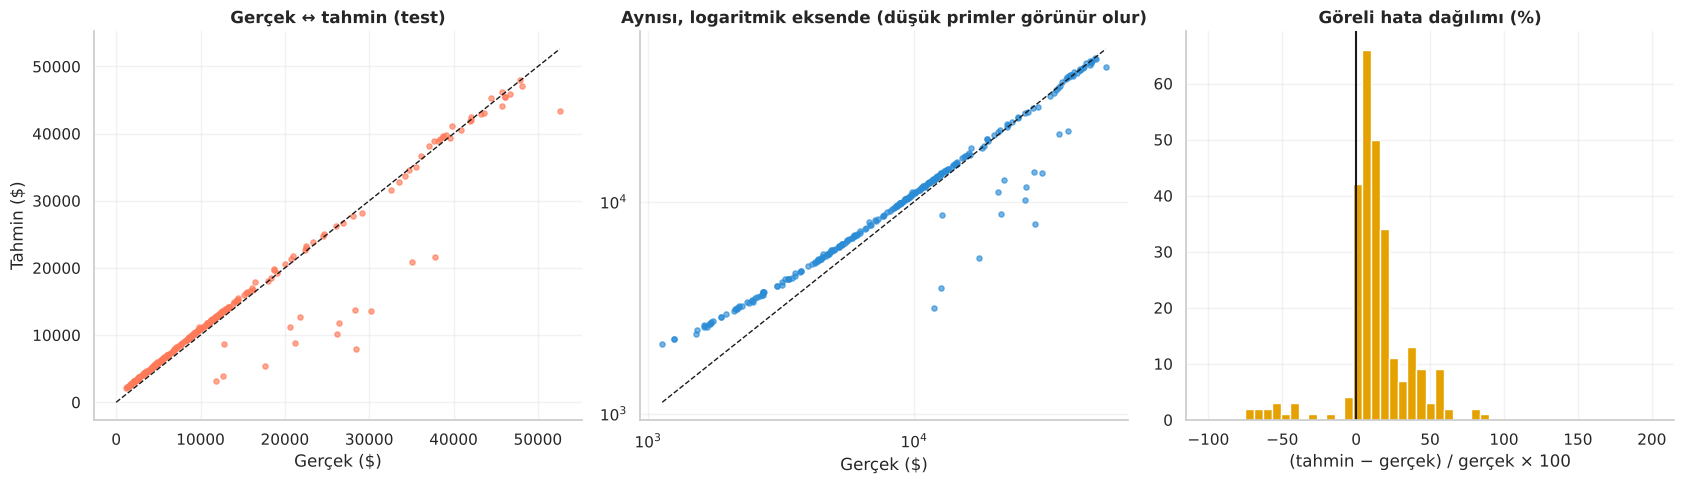

,age,sex,bmi,children,smoker,region,charges,tahmin,hata
33,40,female,41.420,1,no,northwest,28476.73499,7855.0,-20622.0
15,60,male,28.595,0,no,northeast,30259.99556,13599.0,-16661.0
181,43,male,27.800,0,yes,southwest,37829.72420,21685.0,-16145.0
148,49,female,27.100,1,no,southwest,26140.36030,10181.0,-15959.0
253,52,male,36.765,2,no,northwest,26467.09737,11727.0,-14740.0
42,59,female,36.520,1,no,southeast,28287.89766,13799.0,-14489.0
263,45,male,22.895,0,yes,northeast,35069.37452,20872.0,-14198.0
130,48,male,29.600,0,no,southwest,21232.18226,8789.0,-12443.0


📄 Rapor → outputs/reports/19_en_kotu_hatalar.csv


In [30]:
cv_r = sonuc_taze.loc[SECILEN, "RMSE"]; te_r = olc(yte, p_te)["RMSE"]
print(f"Taze katlarda CV RMSE: {cv_r:,.0f} $ | test RMSE: {te_r:,.0f} $ | test/CV = {te_r / cv_r:.2f}")
print(f"Hedef std: eğitim {ytr.std():,.0f} $, test {yte.std():,.0f} $ | test'te 30.000 $ üstü kişi: {(yte > 30000).sum()} / {len(yte)} (eğitimde {(ytr > 30000).sum()} / {len(ytr)})")
rr = olc(yte, kiyas["Ridge · ham"])["RMSE"]
display(Markdown(f"**Dürüst yorum:** Test RMSE (**{te_r:,.0f} $**), çapraz doğrulama tahmininden (**{cv_r:,.0f} $**) belirgin **düşük**. Hedefin dağılımı eğitim ve testte benzer (yukarıda: std ve 30.000 $ üstü oranı), yani fark «test seti kolay» diye açıklanamaz; **tek bir 268 kişilik bölmenin şansı** ve geniş bootstrap aralığı daha makul açıklamadır. **CV skoruna daha çok güvenin**, tek bir test bölmesine değil. Aynı testte basit **Ridge (ham)** de çok yakın (RMSE {rr:,.0f} $); modeller arasındaki küçük farklar şanstan ayırt edilemez."))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].scatter(yte, p_te, s=14, alpha=.65, color=RENK["mercan"]); mx = max(yte.max(), p_te.max()); ax[0].plot([0, mx], [0, mx], "k--", lw=1)
ax[0].set_title("Gerçek ↔ tahmin (test)"); ax[0].set_xlabel("Gerçek ($)"); ax[0].set_ylabel("Tahmin ($)")
ax[1].scatter(yte, p_te, s=14, alpha=.65, color=RENK["gok"]); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].plot([yte.min(), mx], [yte.min(), mx], "k--", lw=1)
ax[1].set_title("Aynısı, logaritmik eksende (düşük primler görünür olur)"); ax[1].set_xlabel("Gerçek ($)")
ax[2].hist((p_te - yte) / yte * 100, bins=np.linspace(-100, 200, 50), color=RENK["amber"], edgecolor="white"); ax[2].axvline(0, color="k")
ax[2].set_title("Göreli hata dağılımı (%)"); ax[2].set_xlabel("(tahmin − gerçek) / gerçek × 100")
plt.tight_layout(); kaydet(fig, "15_final_test"); plt.show()

en_kotu = test.assign(tahmin=p_te.round(0), hata=(p_te - yte).round(0), mutlak=np.abs(p_te - yte).round(0)).sort_values("mutlak", ascending=False).head(8)
display(en_kotu.drop(columns="mutlak")); rapor_kaydet(en_kotu, "19_en_kotu_hatalar", index=False)

### 🎯 12.2 · Dönüşmüş Uzayda Kurulan Asimetrik Güven Aralığı

Dönüşümün **ek bir faydası** var: final model ham hedefle çalışsa bile, hata bandını **Box-Cox uzayında** kurup dolara geri çevirirsek **düşük primlerde dar, yüksek primlerde geniş** (asimetrik) bir aralık elde ederiz. Dolar uzayında tek bir sabit bant (artık kantilleri) ile karşılaştırıyoruz. Bant, **yalnızca eğitimin çapraz doğrulamalı artıklarından** kurulur; test sadece kapsama ölçümü içindir. Hedef kapsama: %90.

Genel kapsama (hedef 0,90): dönüşmüş uzay 0.925 (ort. genişlik 21,959 $) | dolar bandı 0.940 (ort. genişlik 15,054 $)


,Dönüşmüş uzay: kapsama,Dönüşmüş uzay: ort. genişlik ($),Dolar bandı: kapsama,Dolar bandı: ort. genişlik ($)
düşük,0.800,7959.077,0.989,15054.371
orta,0.978,17153.409,0.921,15054.371
yüksek,1.000,40920.872,0.910,15054.371


📄 Rapor → outputs/reports/20_aralik_kapsama.csv


**Okuma:** Box-Cox bandı genişliği tahmine göre ayarlıyor (düşük gruplarda ≈ 7,959 $, yüksek gruplarda ≈ 40,921 $); dolar bandı her yerde sabit (15,054 $). **Ancak ikisi de koşullu kapsamada kusursuz değil:** Box-Cox bandı düşük gruplarda %80'e düşüyor, yüksek grupta %100'e çıkıyor (hedef %90); dolar bandı ise düşük grupta fazla, yüksek grupta az kapsıyor. Asimetrik aralık, **bandın biçimini** gerçeğe yaklaştırır, kalibrasyonu kendiliğinden garanti etmez; küçük veride (268 kişi) bu oranlar da gürültülüdür.

💾 Kaydedildi → outputs/figures/16_aralik.png


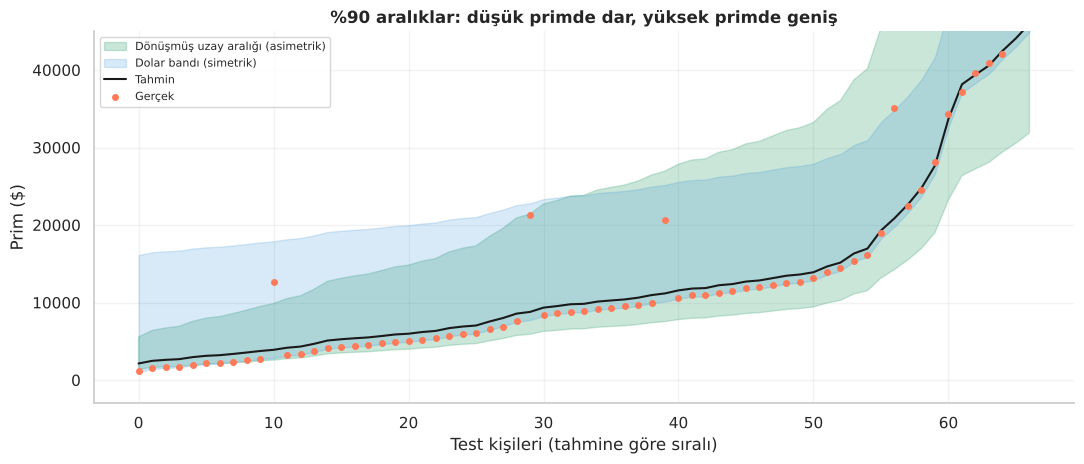

In [31]:
paket = sy.aralik_hesapla(FINAL, Xtr, ytr, q=(0.05, 0.95), rs=RANDOM_STATE, tf=PowerTransformer("box-cox", standardize=True))   # bant Box-Cox uzayında
ar = sy.tahmin_araligi(paket, Xte)
kapsa_bc = ((yte >= ar.alt) & (yte <= ar.ust)).mean(); gen_bc = (ar.ust - ar.alt)

# karşılaştırma: dolar uzayında simetrik bant (artık kantilleri)
q5, q95 = np.quantile(paket["artik_dolar"], [0.05, 0.95])
alt_d, ust_d = p_te + q5, p_te + q95
kapsa_d = ((yte >= alt_d) & (yte <= ust_d)).mean(); gen_d = ust_d - alt_d

duzey = pd.qcut(p_te, 3, labels=["düşük", "orta", "yüksek"])
tab = pd.DataFrame({"Dönüşmüş uzay: kapsama": pd.Series((yte >= ar.alt) & (yte <= ar.ust)).groupby(duzey).mean(),
                    "Dönüşmüş uzay: ort. genişlik ($)": gen_bc.groupby(duzey).mean(),
                    "Dolar bandı: kapsama": pd.Series((yte >= alt_d) & (yte <= ust_d)).groupby(duzey).mean(),
                    "Dolar bandı: ort. genişlik ($)": pd.Series(gen_d).groupby(duzey).mean()})
print(f"Genel kapsama (hedef 0,90): dönüşmüş uzay {kapsa_bc:.3f} (ort. genişlik {gen_bc.mean():,.0f} $) | dolar bandı {kapsa_d:.3f} (ort. genişlik {gen_d.mean():,.0f} $)")
display(tab.round(3)); rapor_kaydet(tab, "20_aralik_kapsama")
display(Markdown(f"**Okuma:** Box-Cox bandı genişliği tahmine göre ayarlıyor (düşük gruplarda ≈ {tab.iloc[0, 1]:,.0f} $, yüksek gruplarda ≈ {tab.iloc[2, 1]:,.0f} $); dolar bandı her yerde sabit ({tab.iloc[0, 3]:,.0f} $). **Ancak ikisi de koşullu kapsamada kusursuz değil:** Box-Cox bandı düşük gruplarda %{tab.iloc[0, 0]*100:.0f}'e düşüyor, yüksek grupta %{tab.iloc[2, 0]*100:.0f}'e çıkıyor (hedef %90); dolar bandı ise düşük grupta fazla, yüksek grupta az kapsıyor. Asimetrik aralık, **bandın biçimini** gerçeğe yaklaştırır, kalibrasyonu kendiliğinden garanti etmez; küçük veride (268 kişi) bu oranlar da gürültülüdür."))

o = np.argsort(p_te)[::4]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(np.arange(len(o)), ar.alt.to_numpy()[o], ar.ust.to_numpy()[o], color=RENK["nane"], alpha=.25, label="Dönüşmüş uzay aralığı (asimetrik)")
ax.fill_between(np.arange(len(o)), alt_d[o], ust_d[o], color=RENK["gok"], alpha=.18, label="Dolar bandı (simetrik)")
ax.plot(p_te[o], color="k", lw=1.5, label="Tahmin"); ax.scatter(np.arange(len(o)), yte[o], s=16, color=RENK["mercan"], zorder=4, label="Gerçek")
ax.set_ylim(-3000, 45000); ax.set_xlabel("Test kişileri (tahmine göre sıralı)"); ax.set_ylabel("Prim ($)"); ax.legend(fontsize=8); ax.set_title("%90 aralıklar: düşük primde dar, yüksek primde geniş")
plt.tight_layout(); kaydet(fig, "16_aralik"); plt.show()

<a id="p13"></a>

<p align="center">
  <img src="assets/proje_13.svg" width="100%" alt="Bölüm 13 · Adalet ve segment">
</p>

### ⚖️ 13.1 · Kim İçin Daha Çok Yanılıyoruz?

Genel skor, grupların **kendi içindeki** hataları saklar. Test setini segmentlere bölüp her segmentte **MAE** ve **sapma %** (tahmin toplamının gerçeğe oranı − 1) hesaplıyoruz. **Sapma > 0:** o gruba **fazla** prim biçiyoruz, **< 0:** **az** prim biçiyoruz. Küçük hücrelerde bootstrap aralığına bakmak şart.

,Boyut,Grup,n,MAE ($),RMSE ($),Sapma %,Sapma alt,Sapma üst
0,yas,18–29,79,1106.4,1665.0,7.7,2.5,13.8
1,yas,30–44,73,1552.5,3525.1,0.4,-6.3,6.2
2,yas,45–64,116,1803.8,3784.3,-2.0,-5.8,2.1
3,bmi,BMI<25,56,1476.8,2899.7,2.3,-5.3,10.1
4,bmi,25–30,85,1652.2,3580.4,-0.3,-7.7,6.4
5,bmi,BMI≥30,127,1471.1,3108.1,0.2,-3.4,3.2
6,cocuk,0,117,1604.4,3282.4,-0.7,-5.3,3.8
7,cocuk,1,65,1940.4,4235.0,-2.3,-11.9,6.2
8,cocuk,2+,86,1117.8,2048.8,3.5,-0.2,6.3
9,cinsiyet,female,140,1355.0,2891.3,3.1,-1.4,6.7


📄 Rapor → outputs/reports/21_segment_final.csv

Sapma aralığı sıfırı DIŞLAYAN segment sayısı: 1 / 17


,Boyut,Grup,n,Sapma %,Sapma alt,Sapma üst
0,yas,18–29,79,7.7,2.5,13.8


📄 Rapor → outputs/reports/22_segment_dogrusal.csv


💾 Kaydedildi → outputs/figures/17_segment_sapma.png


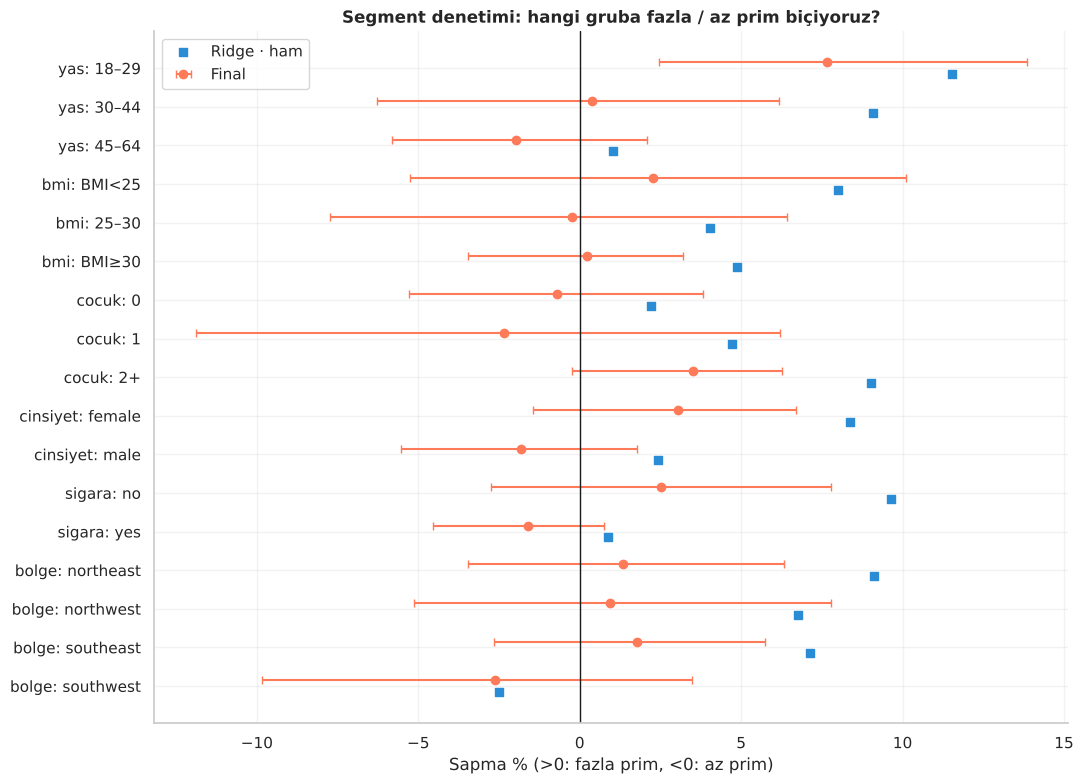

In [32]:
dil = pd.DataFrame({"yas": pd.cut(Xte.age, [17, 29, 44, 64], labels=["18–29", "30–44", "45–64"]),
                    "bmi": pd.cut(Xte.bmi, [0, 25, 30, 100], labels=["BMI<25", "25–30", "BMI≥30"]),
                    "cocuk": pd.cut(Xte.children, [-1, 0, 1, 10], labels=["0", "1", "2+"]),
                    "cinsiyet": Xte.sex, "sigara": Xte.smoker, "bolge": Xte.region})
final_p = pd.Series(p_te); lin_p = pd.Series(kiyas["Ridge · ham"])
def segment_tablo(p):
    satir = []
    for k in dil.columns:
        for g, ix in dil.groupby(k, observed=True).groups.items():
            ix = np.array(ix); yy, pp = yte[ix], p.to_numpy()[ix]
            b = [(pp[i].sum() / yy[i].sum() - 1) * 100 for i in np.random.RandomState(1).randint(0, len(ix), (300, len(ix)))]
            satir.append((k, g, len(ix), np.mean(np.abs(yy - pp)), np.sqrt(np.mean((yy - pp) ** 2)), (pp.sum() / yy.sum() - 1) * 100, np.percentile(b, 2.5), np.percentile(b, 97.5)))
    return pd.DataFrame(satir, columns=["Boyut", "Grup", "n", "MAE ($)", "RMSE ($)", "Sapma %", "Sapma alt", "Sapma üst"])
seg_f, seg_l = segment_tablo(final_p), segment_tablo(lin_p)
display(seg_f.round(1)); rapor_kaydet(seg_f, "21_segment_final", index=False)
isaret = seg_f[(seg_f["Sapma alt"] > 0) | (seg_f["Sapma üst"] < 0)][["Boyut", "Grup", "n", "Sapma %", "Sapma alt", "Sapma üst"]]
print(f"\nSapma aralığı sıfırı DIŞLAYAN segment sayısı: {len(isaret)} / {len(seg_f)}"); display(isaret.round(1)); rapor_kaydet(seg_l, "22_segment_dogrusal", index=False)

fig, ax = plt.subplots(figsize=(11, 8))
seg_f["etiket"] = seg_f.Boyut + ": " + seg_f.Grup.astype(str); y = np.arange(len(seg_f))[::-1]
ax.errorbar(seg_f["Sapma %"], y + .15, xerr=[seg_f["Sapma %"] - seg_f["Sapma alt"], seg_f["Sapma üst"] - seg_f["Sapma %"]], fmt="o", color=RENK["mercan"], capsize=3, label=f"Final")
ax.scatter(seg_l["Sapma %"], y - .15, color=RENK["gok"], marker="s", s=35, label="Ridge · ham")
ax.axvline(0, color="k", lw=1); ax.set_yticks(y); ax.set_yticklabels(seg_f.etiket); ax.legend(); ax.set_xlabel("Sapma % (>0: fazla prim, <0: az prim)")
ax.set_title("Segment denetimi: hangi gruba fazla / az prim biçiyoruz?"); plt.tight_layout(); kaydet(fig, "17_segment_sapma"); plt.show()

💾 Kaydedildi → outputs/figures/18_yas_sigara_isisi.png


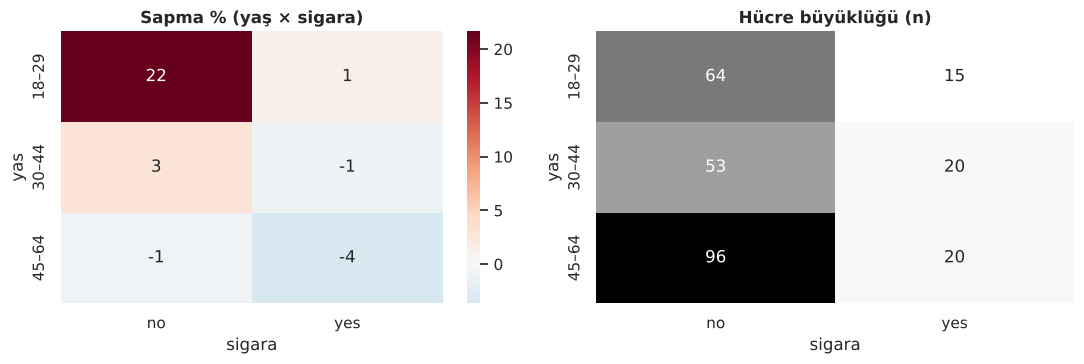

In [33]:
# Isı haritası: yaş bandı × sigara için sapma %
ik = pd.DataFrame({"yas": dil.yas.astype(str), "sigara": dil.sigara, "gercek": yte, "tahmin": p_te}).groupby(["yas", "sigara"]).agg(n=("gercek", "size"), g=("gercek", "sum"), t=("tahmin", "sum"))
ik["sapma"] = (ik.t / ik.g - 1) * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(ik["sapma"].unstack(), annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Sapma % (yaş × sigara)")
sns.heatmap(ik["n"].unstack(), annot=True, fmt="d", cmap="Greys", ax=ax[1], cbar=False); ax[1].set_title("Hücre büyüklüğü (n)")
plt.tight_layout(); kaydet(fig, "18_yas_sigara_isisi"); plt.show()

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Küçük hücrelerde (n < 20) sapma aralıkları **geniş**; «bu gruba kasıtlı fazla prim biçiliyor» gibi bir sonuç çıkarmak için **yetersiz kanıt** var. Yine de **yön** ve **büyüklük** izlenmeli. Bir fiyatlama sistemi için gerçek denetim **daha büyük** veriyle, hukuk ekibiyle yapılmalıdır; bu çalışma **ölçüm yöntemini** gösterir, hüküm vermez.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/proje_14.svg" width="100%" alt="Bölüm 14 · Kalibrasyon ve karar">
</p>

### 📏 14.1 · Kalibrasyon: «Yüz Dolar Dediğimiz Yerde Gerçekten Yüz mü?»

Tahmine göre kişileri 10 eşit gruba (desil) bölüp her grupta **ortalama tahmin** ile **ortalama gerçek** primi karşılaştırıyoruz. Çarpık hedefte yüksek desillerde sapma tipiktir.

,ort_tahmin,ort_gercek,n,sapma %
desil,,,,
1,2799.3,2192.3,27,27.7
2,3954.5,3346.1,27,18.2
3,5488.9,5025.6,27,9.2
4,6777.3,5845.5,26,15.9
5,9129.9,9639.0,27,-5.3
6,10665.6,10692.4,27,-0.3
7,12290.4,12370.3,26,-0.6
8,14300.6,14641.8,27,-2.3
9,22936.4,23793.2,27,-3.6


📄 Rapor → outputs/reports/23_kalibrasyon.csv


💾 Kaydedildi → outputs/figures/19_kalibrasyon.png


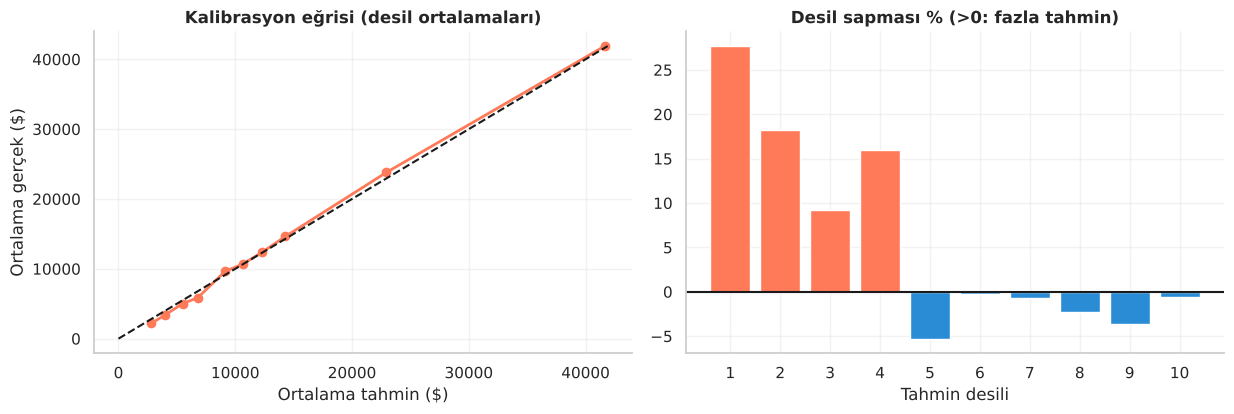

In [34]:
d = pd.DataFrame({"tahmin": p_te, "gercek": yte}); d["desil"] = pd.qcut(d.tahmin.rank(method="first"), 10, labels=range(1, 11))
kal = d.groupby("desil", observed=True).agg(ort_tahmin=("tahmin", "mean"), ort_gercek=("gercek", "mean"), n=("gercek", "size"))
kal["sapma %"] = (kal.ort_tahmin / kal.ort_gercek - 1) * 100
display(kal.round(1)); rapor_kaydet(kal, "23_kalibrasyon")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax[0].plot(kal.ort_tahmin, kal.ort_gercek, "o-", color=RENK["mercan"], lw=2); mx = kal[["ort_tahmin", "ort_gercek"]].max().max(); ax[0].plot([0, mx], [0, mx], "k--")
ax[0].set_title("Kalibrasyon eğrisi (desil ortalamaları)"); ax[0].set_xlabel("Ortalama tahmin ($)"); ax[0].set_ylabel("Ortalama gerçek ($)")
ax[1].bar(kal.index.astype(str), kal["sapma %"], color=[RENK["mercan"] if v > 0 else RENK["gok"] for v in kal["sapma %"]]); ax[1].axhline(0, color="k")
ax[1].set_title("Desil sapması % (>0: fazla tahmin)"); ax[1].set_xlabel("Tahmin desili")
plt.tight_layout(); kaydet(fig, "19_kalibrasyon"); plt.show()

### 💸 14.2 · Maliyete Duyarlı Karar: Az Tahmin Fazla Tahminden Pahalıdır

Sigortacı için **eksik** tahmin (az prim biçmek) zarardır; **fazla** tahmin ise müşteriyi kaybettirebilir. Varsayım (örnek): **eksik tahminin birim maliyeti, fazla tahminin 3 katı.** Tahminleri tek bir **çarpanla** ölçeklemek bu asimetriyi dengeler. Çarpanı **yalnızca eğitimin dışı-kat tahminlerinden** seçiyoruz, testte yalnızca uyguluyoruz.

,Test maliyeti ($/kişi)
Strateji,
"Çarpan 1,00 (ayarsız)",3007.1
Çarpan 1.00 (eğitim OOF'ta seçildi),3007.1


📄 Rapor → outputs/reports/24_maliyet_carpani.csv
Eğitim OOF'ta eksik tahmin oranı: 0.15  (3:1 asimetride ideal ≈ 0,25; SVR'nin ε-duyarsız kaybı tahminleri zaten yüksek kantile yerleştiriyor)
Seçilen çarpan 1.00: tahminler ortalamada %0 yukarı çekildi; testte eksik tahmin oranı 0.13 → 0.13


💾 Kaydedildi → outputs/figures/20_maliyet_carpani.png


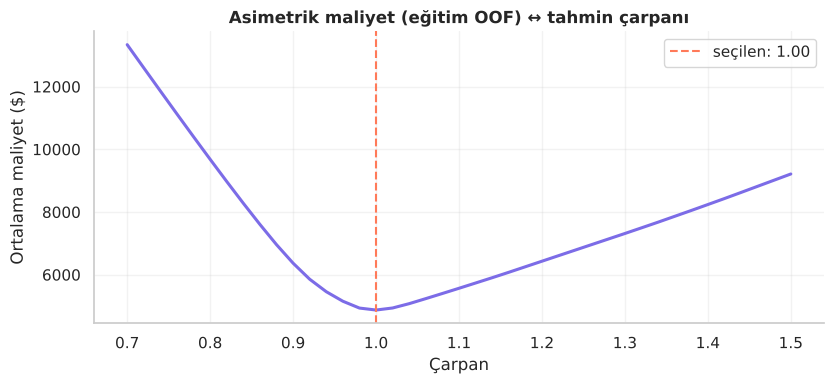

In [35]:
def maliyet(y, p, c_az=3.0, c_fazla=1.0):
    e = p - y
    return np.mean(np.where(e < 0, c_az * (-e), c_fazla * e))

oof_f = paket["oof"]
carpanlar = np.round(np.arange(0.7, 1.51, 0.02), 2)
mal_oof = [maliyet(ytr, oof_f * c) for c in carpanlar]
c_opt = carpanlar[int(np.argmin(mal_oof))]
satir = [("Çarpan 1,00 (ayarsız)", maliyet(yte, p_te)), (f"Çarpan {c_opt:.2f} (eğitim OOF'ta seçildi)", maliyet(yte, p_te * c_opt))]
mt = pd.DataFrame(satir, columns=["Strateji", "Test maliyeti ($/kişi)"]).set_index("Strateji")
display(mt.round(1)); rapor_kaydet(mt, "24_maliyet_carpani")
print(f"Eğitim OOF'ta eksik tahmin oranı: {np.mean(oof_f < ytr):.2f}  (3:1 asimetride ideal ≈ 0,25; SVR'nin ε-duyarsız kaybı tahminleri zaten yüksek kantile yerleştiriyor)")
print(f"Seçilen çarpan {c_opt:.2f}: tahminler ortalamada %{(c_opt - 1) * 100:.0f} yukarı çekildi; testte eksik tahmin oranı {np.mean(p_te < yte):.2f} → {np.mean(p_te * c_opt < yte):.2f}")

fig, ax = plt.subplots(figsize=(8.5, 4)); ax.plot(carpanlar, mal_oof, color=RENK["mor"], lw=2.2); ax.axvline(c_opt, color=RENK["mercan"], ls="--", label=f"seçilen: {c_opt:.2f}"); ax.legend()
ax.set_title("Asimetrik maliyet (eğitim OOF) ↔ tahmin çarpanı"); ax.set_xlabel("Çarpan"); ax.set_ylabel("Ortalama maliyet ($)")
plt.tight_layout(); kaydet(fig, "20_maliyet_carpani"); plt.show()

### 🎯 14.3 · Bütçeli Seçim: En Riskli %10'u Yakalamak

Bir bakım programı **yalnızca en riskli %10'a** (tahmine göre) ulaşabiliyor olsun. Gerçekten en yüksek masraflı %10'un ne kadarını yakalıyoruz? Rastgele seçimle karşılaştıralım.

İlk %10 (27 kişi): gerçek en pahalı %10'un %96'ini yakaladık (rastgele: %10); toplam maliyetin %33'ini kapsıyor.


💾 Kaydedildi → outputs/figures/21_kazanc_egrisi.png


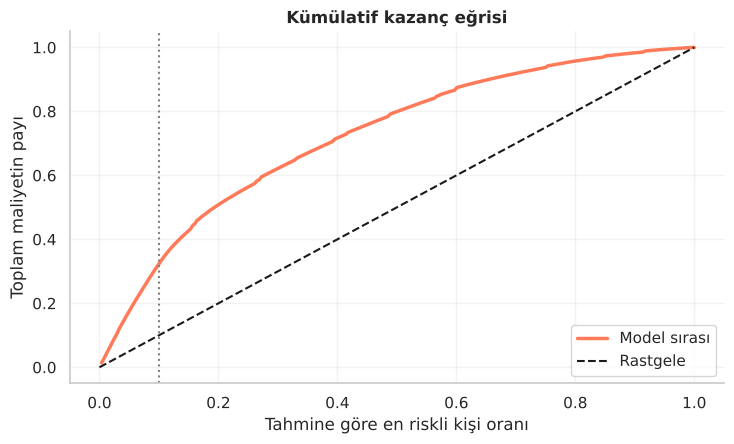

In [36]:
k = int(np.ceil(0.10 * len(yte)))
sec = np.argsort(-p_te)[:k]; gercek_ust = set(np.argsort(-yte)[:k])
yakalama = len(gercek_ust & set(sec)) / k
maliyet_payi = yte[sec].sum() / yte.sum()
rastgele = np.mean([len(gercek_ust & set(np.random.RandomState(s).choice(len(yte), k, replace=False))) / k for s in range(200)])
print(f"İlk %10 ({k} kişi): gerçek en pahalı %10'un %{yakalama*100:.0f}'ini yakaladık (rastgele: %{rastgele*100:.0f}); toplam maliyetin %{maliyet_payi*100:.0f}'ini kapsıyor.")

sirali = np.argsort(-p_te); kum = np.cumsum(yte[sirali]) / yte.sum(); x = np.arange(1, len(yte) + 1) / len(yte)
fig, ax = plt.subplots(figsize=(7.5, 4.6)); ax.plot(x, kum, color=RENK["mercan"], lw=2.5, label="Model sırası"); ax.plot([0, 1], [0, 1], "k--", label="Rastgele"); ax.axvline(0.10, color="gray", ls=":")
ax.set_title("Kümülatif kazanç eğrisi"); ax.set_xlabel("Tahmine göre en riskli kişi oranı"); ax.set_ylabel("Toplam maliyetin payı"); ax.legend()
plt.tight_layout(); kaydet(fig, "21_kazanc_egrisi"); plt.show()

<a id="p15"></a>

<p align="center">
  <img src="assets/proje_15.svg" width="100%" alt="Bölüm 15 · Model kaydı">
</p>

### 💾 15.1 · Modeli Kaydet, Ayrı Bir Süreçte Yükle

Final model (λ ve tüm boru hattı dahil) ve aralık bantları `joblib` ile kaydedilir. **Ayrı bir Python sürecinde** yüklenip aynı tahminleri verdiğini doğruluyoruz; yeni süreçte notebook'taki hiçbir değişken yoktur.

In [37]:
import joblib, json, subprocess, textwrap
MODEL_DIR = Path("outputs/model"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(paket, MODEL_DIR / "prim_modeli.joblib")
ornek = Xte.head(5).copy(); ornek.to_csv(MODEL_DIR / "ornek_musteriler.csv", index=False)
meta = {"final_aday": SECILEN, "model_hedef_donusumu": type(paket["model"].transformer_).__name__, "aralik_donusumu": "Box-Cox", "aralik_lambda": float(paket["tf"].lambdas_[0]),
        "aralik_nominal": 0.90, "q_alt_donusmus": paket["q_alt"], "q_ust_donusmus": paket["q_ust"], "ek_ozellikler": bool(EK_KALSIN),
        "test_RMSE": float(olc(yte, p_te)["RMSE"]), "test_MAE": float(olc(yte, p_te)["MAE"]), "test_R2": float(olc(yte, p_te)["R2"]),
        "surumler": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "lightgbm": lgb.__version__, "xgboost": xgboost.__version__, "catboost": catboost.__version__}}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False)[:900])

# Ayrı süreçte yükleme testi (-I: izole mod; modül yolunu elle ekliyoruz)
kod = textwrap.dedent("""
    import sys, joblib, pandas as pd
    sys.path.insert(0, ".")
    import sigorta_yardimci as sy
    paket = joblib.load("outputs/model/prim_modeli.joblib")
    X = pd.read_csv("outputs/model/ornek_musteriler.csv")
    print(sy.tahmin_araligi(paket, sy.girdi_dogrula(X)).round(2).to_csv(index=False))
""")
cikti = subprocess.run([sys.executable, "-I", "-c", kod], capture_output=True, text=True, cwd=".")
print("Süreç çıkış kodu:", cikti.returncode, cikti.stderr[-300:] if cikti.returncode else "")
yeni = pd.read_csv(__import__("io").StringIO(cikti.stdout))
eski = sy.tahmin_araligi(paket, ornek).round(2).reset_index(drop=True)
print("Ayrı süreç ↔ notebook tahmin farkı (en büyük):", float(np.abs(yeni.values - eski.values).max()))
display(pd.concat([ornek.reset_index(drop=True), yeni], axis=1))

{
  "final_aday": "SVR (RBF) · ayarlı · dönüşüm serbest (ham)",
  "model_hedef_donusumu": "StandardScaler",
  "aralik_donusumu": "Box-Cox",
  "aralik_lambda": 0.05146379689682055,
  "aralik_nominal": 0.9,
  "q_alt_donusmus": -0.4292076301318583,
  "q_ust_donusmus": 0.991504297805568,
  "ek_ozellikler": true,
  "test_RMSE": 3224.99130848389,
  "test_MAE": 1529.7416744406623,
  "test_R2": 0.9278517493815108,
  "surumler": {
    "scikit-learn": "1.9.1",
    "pandas": "3.0.5",
    "lightgbm": "4.7.0",
    "xgboost": "3.4.1",
    "catboost": "1.2.10"
  }
}


Süreç çıkış kodu: 0 
Ayrı süreç ↔ notebook tahmin farkı (en büyük): 0.0


,age,sex,bmi,children,smoker,region,tahmin,alt,ust
0,58,female,27.17,0,no,northwest,13155.00,8902.48,31497.53
1,46,male,25.80,5,no,southwest,11056.97,7456.20,26677.87
2,54,male,30.80,1,yes,southeast,41816.74,28950.90,95297.96
3,30,male,28.69,3,yes,northwest,21296.87,14552.23,49936.29
4,33,female,18.50,1,no,southwest,5698.58,3790.07,14166.07


In [38]:
# ── Üretim benzeri tahmin fonksiyonu + hatalı girdi denemesi ──
def prim_tahmin_et(musteri: dict) -> dict:
    """Tek müşteri için nokta tahmin ve %90 aralık döndürür. Hatalı girdide açık hata verir."""
    X = sy.girdi_dogrula(pd.DataFrame([musteri]))
    s = sy.tahmin_araligi(paket, X).iloc[0]
    return {"tahmin_$": round(float(s.tahmin), 0), "aralik_$": (round(float(s.alt), 0), round(float(s.ust), 0))}

print(prim_tahmin_et({"age": 45, "sex": "female", "bmi": 31.5, "children": 2, "smoker": "no", "region": "northwest"}))
print(prim_tahmin_et({"age": 45, "sex": "female", "bmi": 31.5, "children": 2, "smoker": "yes", "region": "northwest"}))
try:
    prim_tahmin_et({"age": 140, "sex": "female", "bmi": 31.5, "children": 2, "smoker": "no", "region": "northwest"})
except ValueError as hata:
    print("✅ Hatalı girdi yakalandı →", hata)

{'tahmin_$': 9858.0, 'aralik_$': (6632.0, 23906.0)}
{'tahmin_$': 41720.0, 'aralik_$': (28883.0, 95087.0)}
✅ Hatalı girdi yakalandı → age beklenen aralık dışında (18–64) ya da boş


<a id="p16"></a>

<p align="center">
  <img src="assets/proje_16.svg" width="100%" alt="Bölüm 16 · Özet">
</p>

### 📋 16.1 · Proje Özeti

In [39]:
lider = yaris[("RMSE", "ham")].combine(yaris[("RMSE", "box-cox")], min).sort_values().index[0]
bc_iyi_rmse = int((bs["Dolar (RMSE) hükmü"] == "Box-Cox daha iyi").sum()); bc_kotu_rmse = int((bs["Dolar (RMSE) hükmü"] == "Box-Cox daha kötü").sum())
bc_iyi_rmsle = int((bs["Göreli (RMSLE) hükmü"] == "Box-Cox daha iyi").sum()); bc_kotu_rmsle = int((bs["Göreli (RMSLE) hükmü"] == "Box-Cox daha kötü").sum())
ozet = pd.DataFrame([
    ("Algoritma sayısı (taban hariç)", alg_sayisi),
    ("Hedef çarpıklığı (eğitim)", f"{stats.skew(ytr):+.2f} → Box-Cox sonrası {stats.skew(stats.boxcox(ytr, lmbda=lam_bc)):+.2f} (λ = {lam_bc:.3f})"),
    ("Özellik kümesi kararı", "ek özellikler KALDI" if EK_KALSIN else "ek özellikler ÇIKTI"),
    ("Büyük yarış lideri (CV RMSE, en iyi senaryoda)", f"{lider} ({min(yaris.loc[lider, ('RMSE', 'ham')], yaris.loc[lider, ('RMSE', 'box-cox')]):,.0f} $)"),
    ("Bootstrap: Box-Cox dolar (RMSE) hükmü", f"{bc_iyi_rmse} algoritmada daha iyi / {bc_kotu_rmse} daha kötü / {alg_sayisi - bc_iyi_rmse - bc_kotu_rmse} ayırt edilemez"),
    ("Bootstrap: Box-Cox göreli (RMSLE) hükmü", f"{bc_iyi_rmsle} daha iyi / {bc_kotu_rmsle} daha kötü / {alg_sayisi - bc_iyi_rmsle - bc_kotu_rmsle} ayırt edilemez"),
    ("Seçilen final aday", SECILEN),
    ("Final test RMSE / MAE / R²", f"{olc(yte, p_te)['RMSE']:,.0f} $ / {olc(yte, p_te)['MAE']:,.0f} $ / {olc(yte, p_te)['R2']:.3f}"),
    ("Basit kural (sigara × obez) test RMSE", f"{olc(yte, p_kural)['RMSE']:,.0f} $"),
    ("%90 aralık kapsaması (dönüşmüş uzay ↔ dolar bandı)", f"{kapsa_bc:.2f} ↔ {kapsa_d:.2f}"),
    ("Maliyet çarpanı (3:1 asimetri)", f"{c_opt:.2f}"),
    ("En riskli %10'u yakalama", f"%{yakalama*100:.0f} (rastgele %{rastgele*100:.0f})"),
], columns=["Ölçüm", "Değer"])
display(ozet.style.hide(axis="index")); rapor_kaydet(ozet, "99_proje_ozeti", index=False)

Ölçüm,Değer
Algoritma sayısı (taban hariç),27
Hedef çarpıklığı (eğitim),+1.51 → Box-Cox sonrası -0.01 (λ = 0.051)
Özellik kümesi kararı,ek özellikler KALDI
"Büyük yarış lideri (CV RMSE, en iyi senaryoda)","Yığın (Ridge meta) (4,643 $)"
Bootstrap: Box-Cox dolar (RMSE) hükmü,2 algoritmada daha iyi / 15 daha kötü / 10 ayırt edilemez
Bootstrap: Box-Cox göreli (RMSLE) hükmü,19 daha iyi / 0 daha kötü / 8 ayırt edilemez
Seçilen final aday,SVR (RBF) · ayarlı · dönüşüm serbest (ham)
Final test RMSE / MAE / R²,"3,225 $ / 1,530 $ / 0.928"
Basit kural (sigara × obez) test RMSE,"5,294 $"
%90 aralık kapsaması (dönüşmüş uzay ↔ dolar bandı),0.93 ↔ 0.94


📄 Rapor → outputs/reports/99_proje_ozeti.csv


<p align="center">
  <img src="assets/kapanis_proje.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🎛️</h3><b>Dönüşüm bir düğmedir</b><br><sub><i>λ ölçüte göre seçilir</i></sub><br><br>Çana en çok benzeyen λ ile hatası en düşük λ <b>aynı olmak zorunda değil</b><br><br></td><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>λ her katta eğitimden</b><br><sub><i>TransformedTargetRegressor</i></sub><br><br>λ da öğrenilen bir şeydir; sızıntısız boru hattında yalnızca eğitimden öğrenilir<br><br></td><td width="33%" valign="top" align="center"><h3>🌳</h3><b>Herkes kazanmaz</b><br><sub><i>ağaçlar sıraya bakar</i></sub><br><br>Doğrusal/uzaklık modelleri dönüşümden etkilenir; güçlü ağaç toplulukları az etkilenir<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>↩️</h3><b>Geri dönüş yanlılığı</b><br><sub><i>ortanca ≠ ortalama</i></sub><br><br>Toplam maliyet tahmininde ters dönüşümün <b>ortalamada düşük kalma</b> eğilimini ölçün<br><br></td><td width="33%" valign="top" align="center"><h3>🎯</h3><b>Asimetrik aralık</b><br><sub><i>dönüşmüş uzayda bant</i></sub><br><br>Çarpık hedefte dönüşmüş uzayda kurulan bant düşük primde dar, yüksek primde geniştir<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>Adalet bir ölçüm işidir</b><br><sub><i>segment, sapma %, ablasyon</i></sub><br><br>Etik açıdan hassas sütunların maliyeti ve segment sapmaları <b>ölçülerek</b> konuşulur<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Box-Cox hedef neden bazı modellerde RMSLE'yi iyileştirirken RMSE'yi kötüleştirebilir?</summary>

RMSLE göreli hatayı ölçer; dönüşmüş uzayda eğitilen model göreli doğruluğu hedefler. RMSE ise dolar hatasıdır ve büyük primlerden etkilenir. Ters dönüşüm büyük değerlerde sapmaları büyüttüğü için dolar hatası artabilir.
</details>

<details><summary><b>2.</b> λ'yı neden her doğrulama katında yeniden öğrenmeliyiz?</summary>

λ, hedef verisinden hesaplanan bir parametredir. Doğrulama katının hedefi hesaba katılırsa sızıntı olur ve skor iyimserleşir. `TransformedTargetRegressor` her katın eğitim kısmından λ'yı öğrenir.
</details>

<details><summary><b>3.</b> Ağaç tabanlı bir modelde özellik dönüşümü neden etkisizdir?</summary>

Ağaçlar yalnızca değerlerin sırasına göre bölme yapar. Sırayı bozmayan bir dönüşüm aynı kişileri aynı yaprağa gönderir. (Hedef dönüşümü ise kayıp fonksiyonunu değiştirdiği için etkili olabilir.)
</details>

<details><summary><b>4.</b> Bootstrap aralığı sıfırı kesiyorsa ne söyleyebiliriz?</summary>

İki senaryo arasındaki farkın şanstan ayırt edilemediğini; «hangisi daha iyi» iddiasının bu veriyle desteklenmediğini.
</details>

<details><summary><b>5.</b> Dönüşmüş uzayda kurulan güven aralığı dolar uzayında neden asimetrik çıkar?</summary>

Ters dönüşüm doğrusal değildir; dönüşmüş uzayda simetrik olan bant, büyük değerlerde daha çok açılır. Böylece yüksek primde geniş, düşük primde dar aralık elde edilir.
</details>

<details><summary><b>6.</b> `sex` ve `region` çıkarıldığında skor çok düşmüyorsa ne yapmalıyız?</summary>

Etik/hukuki açıdan hassas sütunlardan vazgeçmek ucuz demektir; fiyatlama ekibi ve hukuk ekibiyle bu sütunların kullanılıp kullanılmayacağı tartışılmalıdır. Ablasyon bu tartışmaya sayı sağlar.
</details>

### 🏠 Ödevler

1. **Başka hedef:** `bmi` sütununu hedef alıp aynı dönüşüm laboratuvarını yeniden çalıştırın. Çarpıklık düşük olduğunda dönüşüm hâlâ gerekli mi?
2. **λ sınırı:** 9.2'deki tarama aralığını −1…2'ye genişletin. Çok büyük λ ne yapıyor?
3. **Başka aile:** `RANSAC`, `Huber` gibi sağlam (robust) doğrusal modellerin Box-Cox'tan nasıl etkilendiğini 7. bölüm tablosundan okuyup nedenini yazın.
4. **Asimetri:** 14.2'deki 3:1 maliyet oranını 1:3'e çevirin. Seçilen çarpan nasıl değişiyor?
5. **Smearing:** 9.4'teki karşılaştırmayı `Gradient Boosting` için tekrarlayın. Düzeltme yardımcı oluyor mu?
6. **Kantil:** Kantil dönüşümünü tavan sorunuyla birlikte inceleyin: tahminlerin en büyüğü eğitimdeki en büyük primi aşabiliyor mu?

### 📚 Kaynakça

Bu çalışmadaki fikirler aşağıdaki kaynaklara dayanır. Dolaylı (ikincil) aktarımlar metinde «…'den aktarma» ile belirtilmiştir.

- Atkinson, A. C., Riani, M., & Corbellini, A. (2021). The Box–Cox transformation: Review and extensions. *Statistical Science, 36*(2), 239–255. https://doi.org/10.1214/20-STS778
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x
- Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605–610. https://doi.org/10.1080/01621459.1983.10478017
- Lantz, B. (2013). *Machine learning with R*. Packt Publishing. (Sigorta veri setinin özgün kaynağı)
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*, 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Raymaekers, J., & Rousseeuw, P. J. (2024). Transforming variables to central normality. *Machine Learning, 113*(8), 4953–4975. https://doi.org/10.1007/s10994-021-05960-5
- Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954